# Embodied Design with Computer Vision

You'll make an artwork **respond to your hands and face** through the webcam, then record a short video of you performing with it.

<br>

You can move your hand to make a cloud follow you. Then, choose a gesture that makes it rain.

**Your challenge:** create one interaction and record a short performance.

<br>

Start by clicking on "File" > "Save a copy in drive". Work on the copy that opens up.


Once you're ready, run the setup cell below ↓.

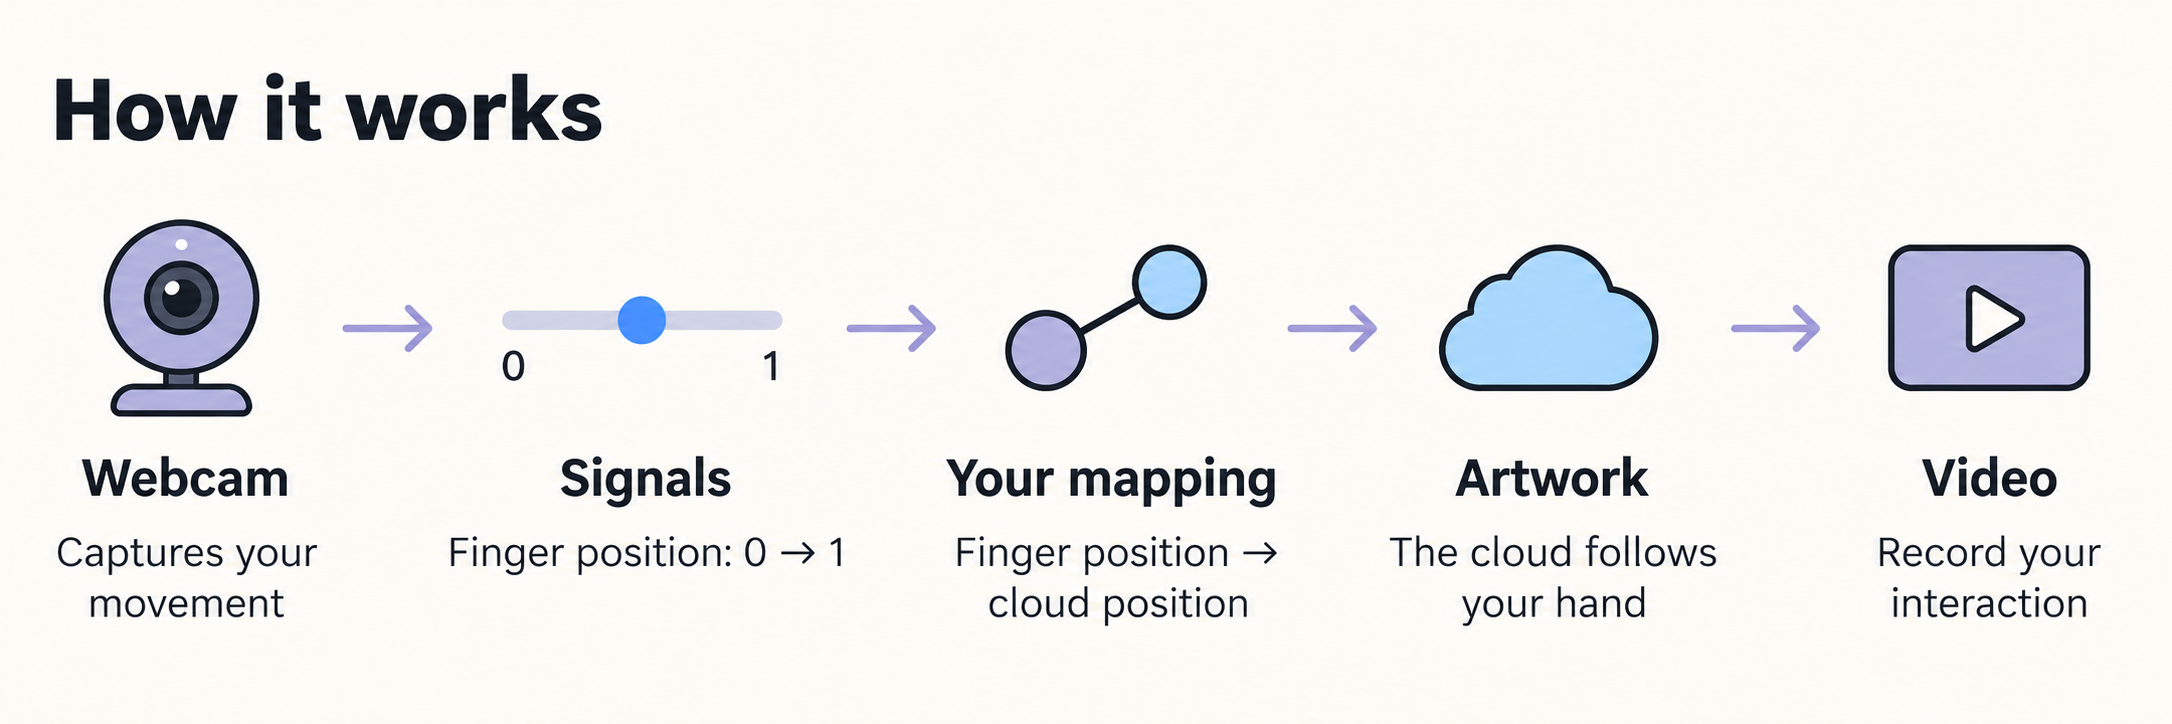

```
 webcam  →  signals            →  your mappings          →  artwork          →  🎥 video
            index.x, pinch,       "pinch → cloud size"       cloud, creature,
            mouth.open, fist…     "fist  → rain"             seaside, fluid
```

There are two kinds of mapping:
* **Dials** are smooth controls. A *signal* (a number from 0 to 1, like where your finger is) continuously drives a *visual parameter* (like the cloud's size).
* **Triggers** are one-off events. A *gesture* (like a fist) fires an *action* (like rain).

| | **Beginner track** | **Advanced track** |
|---|---|---|
| Gestures | train your own (Step 2) | MediaPipe's built-in gestures |
| Mapping | pick signals → dials, gestures → actions | ranges, inversion, smoothing, zones & two-hand controls in JS |
| Artwork | choose from the gallery | modify the gallery, or write a new one with new visual parameters (p5.js) |

**Timeline (45 min):** Setup + Step 1 (5 min) · Step 2 (8 min) · Step 3 (20 min) · record + save (5 min) · showcase (5 min)

> Use **Chrome** on a laptop with a webcam. When the browser asks, **allow camera access**. Nothing leaves your computer, except the video you choose to save.

## 0 · Setup
Click ▶ on the cell below. It takes about 2 seconds.

In [1]:
#@title Teacher-provided studio tools — run once { display-mode: "form" }
# Everything visual (camera, tracking, artwork, recording) runs live in your browser.
# Python is where you choose an artwork, write mappings, and save your video.
import json, os, uuid, base64, difflib, glob, shutil, subprocess
from types import SimpleNamespace
from IPython.display import display, HTML

try:
    from google.colab import output as _colab_output
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# ---------------------------------------------------------------- what the camera gives you
# Every signal is a number between 0 and 1, so any signal can drive any visual parameter.
SIGNALS = {
    "index.x":       ("hand", 0.5, "index fingertip position, left (0) → right (1)"),
    "index.y":       ("hand", 0.5, "index fingertip position, top (0) → bottom (1)"),
    "palm.x":        ("hand", 0.5, "palm centre, left → right"),
    "palm.y":        ("hand", 0.5, "palm centre, top → bottom"),
    "pinch":         ("hand", 1.0, "thumb–index gap: 0 = touching, 1 = wide apart"),
    "hand.open":     ("hand", 1.0, "0 = fist, 1 = open hand"),
    "hand.size":     ("hand", 0.5, "how big your hand looks (closer to the camera = bigger)"),
    "hand.angle":    ("hand", 0.25, "direction the index finger points, once around the circle (0.25 = up)"),
    "point.x":       ("hand", 0.5, "pointing direction, horizontal: 0 = pointing left, 1 = pointing right"),
    "point.y":       ("hand", 0.5, "pointing direction, vertical: 0 = pointing up, 1 = pointing down"),
    "hand.speed":    ("hand", 0.0, "how fast your fingertip is moving"),
    "hand.visible":  ("hand", 0.0, "1 when a hand is in view, else 0"),
    "hand2.x":       ("two hands", 0.5, "second hand's index fingertip, left → right"),
    "hand2.y":       ("two hands", 0.5, "second hand's index fingertip, top → bottom"),
    "hands.distance":("two hands", 0.0, "distance between your two hands (0 if only one)"),
    "face.x":        ("face", 0.5, "nose position, left → right"),
    "face.y":        ("face", 0.5, "nose position, top → bottom"),
    "mouth.open":    ("face", 0.0, "0 = closed, 1 = wide open"),
    "smile":         ("face", 0.0, "how much you smile"),
    "brows.up":      ("face", 0.0, "eyebrows raised"),
    "blink":         ("face", 0.0, "eyes closed amount"),
    "head.tilt":     ("face", 0.5, "head tilted left (0) … level (0.5) … right (1)"),
    "head.turn":     ("face", 0.5, "head turned left (0) … forward (0.5) … right (1)"),
    "face.visible":  ("face", 0.0, "1 when a face is in view"),
}
FACE_SIGNALS = {k for k, v in SIGNALS.items() if v[0] == "face"}
BUILTIN_GESTURES = ["closed_fist", "open_palm", "pointing_up", "thumb_up", "thumb_down", "victory", "iloveyou"]
FACE_EVENTS = ["mouth_open", "smile", "brows_up", "blink"]
DEFAULT_GESTURES = ["open_palm", "fist", "point", "peace", "rest"]

# ---------------------------------------------------------------- the gallery
# params: name -> (min, max, default, what it does)
ARTWORKS = {
    "cloud": dict(
        title="A cloud in the sky",
        params={"x": (0, 1, 0.5, "cloud position left → right"),
                "y": (0.1, 0.8, 0.35, "cloud height (top → bottom)"),
                "size": (0.4, 2.2, 1.0, "cloud size"),
                "puff": (0, 1, 0.4, "how much the cloud puffs and breathes"),
                "darkness": (0, 1, 0.0, "white → storm grey"),
                "sky": (0, 1, 0.2, "time of day: day → sunset → night"),
                "wind": (0, 1, 0.3, "wind speed (small clouds, rain angle)")},
        actions={"rain": "start/stop rain", "snow": "start/stop snow",
                 "lightning": "a lightning strike", "rainbow": "show/hide a rainbow"}),
    "creature": dict(
        title="A blob creature",
        params={"x": (0.1, 0.9, 0.5, "position left → right"),
                "y": (0.2, 0.9, 0.6, "position up → down"),
                "size": (0.5, 2.0, 1.0, "body size"),
                "mouth": (0, 1, 0.1, "mouth open"),
                "eyes": (0.5, 1.6, 1.0, "eye size"),
                "gaze_x": (0, 1, 0.5, "where it looks, left → right"),
                "gaze_y": (0, 1, 0.5, "where it looks, up → down"),
                "hue": (0, 360, 150, "body colour (colour wheel)"),
                "wobble": (0, 1, 0.3, "how jelly-like it wobbles")},
        actions={"jump": "jump", "blink": "blink once", "color": "change colour",
                 "sleep": "fall asleep / wake up", "hearts": "float some hearts"}),
    "seaside": dict(
        title="A seaside painting",
        params={"sun": (0, 1, 0.6, "sun height: night → sunset → noon"),
                "sun_x": (0.05, 0.95, 0.7, "sun position left → right"),
                "waves": (0, 1, 0.3, "how rough the sea is"),
                "hills": (0, 1, 0.5, "how tall the hills are"),
                "clouds": (0, 1, 0.3, "cloud cover")},
        actions={"shooting_star": "a shooting star", "birds": "a flock of birds",
                 "fireworks": "fireworks", "boat": "a sailboat crosses"}),
    "fluid": dict(
        title="Fluid paint",
        params={"x": (0, 1, 0.5, "brush position left → right (moving it stirs the paint)"),
                "y": (0, 1, 0.5, "brush position top → bottom"),
                "size": (0.05, 1, 0.3, "brush size"),
                "hue": (0, 360, 200, "paint colour (colour wheel)"),
                "flow": (0, 1, 0.5, "how much paint comes out"),
                "force": (0, 1, 0.5, "how hard the brush pushes the paint"),
                "swirl": (0, 50, 20, "how swirly the paint is"),
                "fade": (0, 1, 0.2, "how fast paint fades away")},
        actions={"drop": "drop a big blob of paint", "burst": "a ring of colours",
                 "new_color": "switch to a new colour", "rainbow": "cycle colours on/off",
                 "clear": "clean the canvas"}),
}

GESTURE_FILE = "my_gestures.json"
REC_DIR = "recordings"
os.makedirs(REC_DIR, exist_ok=True)

STUDIO_JS = r"""(async function () {
"use strict";
const UID = "__UID__";
const root = document.getElementById(UID);
const CFG = JSON.parse(document.getElementById(UID + "-cfg").textContent);
const META = CFG.meta;

// ---------------------------------------------------------------- constants
const URLS = Object.assign({
  mediapipe: "https://cdn.jsdelivr.net/npm/@mediapipe/tasks-vision@0.10.14/vision_bundle.mjs",
  wasm: "https://cdn.jsdelivr.net/npm/@mediapipe/tasks-vision@0.10.14/wasm",
  gestureModel: "https://storage.googleapis.com/mediapipe-models/gesture_recognizer/gesture_recognizer/float16/1/gesture_recognizer.task",
  faceModel: "https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task",
  p5: "https://cdn.jsdelivr.net/npm/p5@1.11.13/lib/p5.min.js",
}, CFG.urls || {});
const W = 960, H = 540;              // artwork canvas size (16:9)
const REC_W = 1280, REC_H = 720;     // recorded video size
const STABLE_FRAMES = 5;             // frames a gesture must hold before it counts
const MIN_CONF = 0.6;

// ---------------------------------------------------------------- helpers
const clamp = (v, a = 0, b = 1) => Math.max(a, Math.min(b, v));
const lerp = (a, b, t) => a + (b - a) * t;
const map = (v, a, b, c = 0, d = 1) => c + (d - c) * clamp((v - a) / (b - a || 1e-9));
const dist = (p, q) => Math.hypot(p.x - q.x, p.y - q.y);
const el = (tag, cls, html) => { const e = document.createElement(tag); if (cls) e.className = cls; if (html != null) e.innerHTML = html; return e; };
const fmt = (v) => (typeof v === "number" ? v.toFixed(2) : String(v));
function resizeFrame() {
  try { google.colab.output.setIframeHeight(document.documentElement.scrollHeight + 20, true); } catch (e) {}
}
function loadScript(src) {
  return new Promise((res, rej) => {
    if (window.p5) return res();
    const s = document.createElement("script"); s.src = src; s.onload = res; s.onerror = () => rej(new Error("Could not load " + src));
    document.head.appendChild(s);
  });
}
function colabCall(name, args) {
  try {
    if (window.google && google.colab && google.colab.kernel) return google.colab.kernel.invokeFunction(name, args, {});
  } catch (e) {}
  return Promise.reject(new Error("not in Colab"));
}

// ---------------------------------------------------------------- layout
root.classList.add("vs");
root.innerHTML = "";
const header = el("div", "vs-header");
const status = el("div", "vs-status", "Starting…");
header.appendChild(el("div", "vs-title", CFG.title || ""));
header.appendChild(status);
root.appendChild(header);
const setStatus = (html, kind) => { status.innerHTML = html; status.dataset.kind = kind || ""; };

// ---------------------------------------------------------------- camera + tracker
let video = null, tracker = null, inputMode = CFG.input || "camera";

async function startCamera() {
  video = document.createElement("video");
  video.playsInline = true; video.muted = true; video.autoplay = true;
  const stream = await navigator.mediaDevices.getUserMedia({ video: { width: 640, height: 360, facingMode: "user" }, audio: false });
  video.srcObject = stream;
  await video.play();
  await new Promise((r) => (video.readyState >= 2 ? r() : (video.onloadeddata = r)));
}
function stopCamera() {
  if (video && video.srcObject) video.srcObject.getTracks().forEach((t) => t.stop());
}

async function initTracker(needFace) {
  const vision = await import(URLS.mediapipe);
  const fileset = await vision.FilesetResolver.forVisionTasks(URLS.wasm);
  async function make(cls, opts) {
    try { return await cls.createFromOptions(fileset, Object.assign({}, opts, { baseOptions: Object.assign({}, opts.baseOptions, { delegate: "GPU" }) })); }
    catch (e) { return await cls.createFromOptions(fileset, Object.assign({}, opts, { baseOptions: Object.assign({}, opts.baseOptions, { delegate: "CPU" }) })); }
  }
  const gesture = await make(vision.GestureRecognizer, { baseOptions: { modelAssetPath: URLS.gestureModel }, runningMode: "VIDEO", numHands: 2 });
  const face = needFace ? await make(vision.FaceLandmarker, { baseOptions: { modelAssetPath: URLS.faceModel }, runningMode: "VIDEO", numFaces: 1, outputFaceBlendshapes: true }) : null;
  let lastVideoTime = -1, lastTs = 0, frame = 0, cache = { hands: [], face: null };
  return {
    // Returns {hands:[{lm, handed, gesture, gscore}], face:{lm, bs}|null}. Landmarks are mirrored (selfie view).
    process(now) {
      if (!video || video.readyState < 2 || video.currentTime === lastVideoTime) return cache;
      lastVideoTime = video.currentTime;
      const ts = Math.max(now, lastTs + 1); lastTs = ts; frame++;
      const out = { hands: [], face: cache.face };
      const g = gesture.recognizeForVideo(video, ts);
      (g.landmarks || []).forEach((lm, i) => {
        const cat = (g.gestures && g.gestures[i] && g.gestures[i][0]) || { categoryName: "None", score: 0 };
        const hd = (g.handedness && g.handedness[i] && g.handedness[i][0]) || { categoryName: "Right" };
        out.hands.push({ lm: lm.map((p) => ({ x: 1 - p.x, y: p.y, z: p.z })), handed: hd.categoryName, gesture: cat.categoryName, gscore: cat.score });
      });
      if (face && frame % 2 === 0) {               // face every other frame keeps things fast
        const f = face.detectForVideo(video, ts + 0.5);
        if (f.faceLandmarks && f.faceLandmarks.length) {
          const bs = {};
          ((f.faceBlendshapes && f.faceBlendshapes[0] && f.faceBlendshapes[0].categories) || []).forEach((c) => (bs[c.categoryName] = c.score));
          out.face = { lm: f.faceLandmarks[0].map((p) => ({ x: 1 - p.x, y: p.y, z: p.z })), bs };
        } else out.face = null;
      }
      cache = out;
      return out;
    },
  };
}

// ---------------------------------------------------------------- signals
// Every signal is a number in 0..1 so that any signal can drive any parameter.
function makeSignals() {
  const s = {};
  for (const k of Object.keys(META.signals)) s[k] = META.signals[k].default;
  let prevTip = null, speed = 0;
  s._vx = 0; s._vy = 0;
  function handFeatures(h) {
    const lm = h.lm, size = Math.max(dist(lm[0], lm[9]), 1e-3);
    return { lm, size };
  }
  return {
    s,
    fromTracking(raw, dt) {
      const hands = raw.hands.slice().sort((a, b) => dist(b.lm[0], b.lm[9]) - dist(a.lm[0], a.lm[9]));
      s["hand.visible"] = hands.length ? 1 : 0;
      if (hands.length) {
        const { lm, size } = handFeatures(hands[0]);
        const tip = lm[8];
        s["index.x"] = tip.x; s["index.y"] = tip.y;
        s["palm.x"] = (lm[0].x + lm[9].x) / 2; s["palm.y"] = (lm[0].y + lm[9].y) / 2;
        s["pinch"] = map(dist(lm[4], lm[8]) / size, 0.15, 1.1);
        const reach = [8, 12, 16, 20].reduce((a, i) => a + dist(lm[i], lm[0]), 0) / 4 / size;
        s["hand.open"] = map(reach, 1.0, 1.85);
        s["hand.size"] = map(size, 0.05, 0.3);
        const ang = Math.atan2(-(lm[8].y - lm[5].y), lm[8].x - lm[5].x);
        s["hand.angle"] = ((ang / (2 * Math.PI)) + 1) % 1;
        s["point.x"] = (Math.cos(ang) + 1) / 2;
        s["point.y"] = (1 - Math.sin(ang)) / 2;
        if (prevTip && dt > 0) {
          const vx = (tip.x - prevTip.x) / dt, vy = (tip.y - prevTip.y) / dt;
          s._vx = vx; s._vy = vy;
          speed = lerp(speed, Math.hypot(vx, vy), 0.3);
        }
        prevTip = { x: tip.x, y: tip.y };
        s["hand.speed"] = clamp(speed / 2.5);
        if (hands.length > 1) {
          const l2 = hands[1].lm;
          s["hand2.x"] = l2[8].x; s["hand2.y"] = l2[8].y;
          s["hands.distance"] = map(dist(lm[9], l2[9]), 0.05, 0.8);
        } else s["hands.distance"] = 0;
      } else { prevTip = null; speed = lerp(speed, 0, 0.2); s["hand.speed"] = clamp(speed / 2.5); }
      const f = raw.face;
      s["face.visible"] = f ? 1 : 0;
      if (f) {
        const lm = f.lm, bs = f.bs;
        s["face.x"] = lm[1].x; s["face.y"] = lm[1].y;
        s["mouth.open"] = map(bs.jawOpen || 0, 0.02, 0.6);
        s["smile"] = map(((bs.mouthSmileLeft || 0) + (bs.mouthSmileRight || 0)) / 2, 0.05, 0.8);
        s["brows.up"] = map(bs.browInnerUp || 0, 0.05, 0.8);
        s["blink"] = clamp(((bs.eyeBlinkLeft || 0) + (bs.eyeBlinkRight || 0)) / 2);
        const eyeA = lm[33].x < lm[263].x ? lm[33] : lm[263];
        const eyeB = eyeA === lm[33] ? lm[263] : lm[33];
        const roll = Math.atan2(eyeB.y - eyeA.y, eyeB.x - eyeA.x);
        s["head.tilt"] = map(roll, -0.5, 0.5);
        const l = lm[234], r = lm[454];
        s["head.turn"] = map((lm[1].x - Math.min(l.x, r.x)) / (Math.abs(r.x - l.x) || 1e-3), 0.2, 0.8);
      }
      return s;
    },
    fromMouse(m, dt) {
      s["hand.visible"] = m.inside ? 1 : 0;
      s["face.visible"] = 0;
      if (prevTip && dt > 0) { s._vx = (m.x - prevTip.x) / dt; s._vy = (m.y - prevTip.y) / dt; speed = lerp(speed, Math.hypot(s._vx, s._vy), 0.3); }
      prevTip = { x: m.x, y: m.y };
      s["index.x"] = s["palm.x"] = m.x; s["index.y"] = s["palm.y"] = m.y;
      s["pinch"] = m.down ? 0 : 1; s["hand.open"] = m.down ? 0 : 1;
      s["hand.speed"] = clamp(speed / 2.5);
      s["point.x"] = m.x; s["point.y"] = m.y;
      s["hand.angle"] = ((Math.atan2(-(m.y - 0.5), m.x - 0.5) / (2 * Math.PI)) + 1) % 1;
      s["mouth.open"] = m.down ? 1 : 0;
      return s;
    },
  };
}

// ---------------------------------------------------------------- gesture classifier (k-nearest neighbours on hand landmarks)
function handVector(h) {
  const lm = h.lm, size = Math.max(dist(lm[0], lm[9]), 1e-3);
  const flip = h.handed === "Left" ? -1 : 1;     // left and right hands look the same to the classifier
  const v = [];
  for (let i = 1; i < 21; i++) { v.push(((lm[i].x - lm[0].x) * flip) / size, (lm[i].y - lm[0].y) / size); }
  return v;
}
function makeKNN(samples) {
  const data = (samples || []).map((s) => ({ label: s.label, f: s.f }));
  return {
    data,
    add(label, f) { data.push({ label, f: f.map((x) => Math.round(x * 1000) / 1000) }); },
    clear(label) { for (let i = data.length - 1; i >= 0; i--) if (data[i].label === label) data.splice(i, 1); },
    count(label) { return data.reduce((a, d) => a + (d.label === label ? 1 : 0), 0); },
    predict(f) {
      if (data.length < 3) return { label: "none", conf: 0 };
      const k = Math.min(7, data.length);
      const best = [];
      for (const d of data) {
        let s = 0; for (let i = 0; i < f.length; i++) { const q = f[i] - d.f[i]; s += q * q; }
        if (best.length < k || s < best[best.length - 1][0]) { best.push([s, d.label]); best.sort((a, b) => a[0] - b[0]); if (best.length > k) best.pop(); }
      }
      const votes = {}; best.forEach(([, l]) => (votes[l] = (votes[l] || 0) + 1));
      let label = "none", n = 0; for (const l in votes) if (votes[l] > n) { n = votes[l]; label = l; }
      return { label, conf: n / k };
    },
  };
}

// ---------------------------------------------------------------- events: stable gestures + face events
function makeEvents() {
  let cand = "none", count = 0, stable = "none";
  const face = { mouth_open: false, smile: false, brows_up: false, blink: false };
  const FACE_RULES = {
    mouth_open: ["mouth.open", 0.6, 0.35], smile: ["smile", 0.6, 0.35],
    brows_up: ["brows.up", 0.6, 0.35], blink: ["blink", 0.55, 0.3],
  };
  return {
    get stable() { return stable; },
    update(label, conf, s) {
      const fired = [];
      if (conf < MIN_CONF) label = "none";
      if (label === cand) count++; else { cand = label; count = 1; }
      if (count >= STABLE_FRAMES && cand !== stable) { stable = cand; if (stable !== "none") fired.push(stable); }
      if (s["face.visible"]) {
        for (const [ev, [sig, on, off]] of Object.entries(FACE_RULES)) {
          if (!face[ev] && s[sig] > on) { face[ev] = true; fired.push(ev); }
          else if (face[ev] && s[sig] < off) face[ev] = false;
        }
      }
      return fired;
    },
    fire(name) { return [name]; },
  };
}

// ---------------------------------------------------------------- drawing the camera view with landmarks
const HAND_LINKS = [[0,1],[1,2],[2,3],[3,4],[0,5],[5,6],[6,7],[7,8],[5,9],[9,10],[10,11],[11,12],[9,13],[13,14],[14,15],[15,16],[13,17],[17,18],[18,19],[19,20],[0,17]];
function drawCamera(ctx, w, h, raw, opts = {}) {
  ctx.save();
  if (video && video.readyState >= 2) { ctx.translate(w, 0); ctx.scale(-1, 1); ctx.drawImage(video, 0, 0, w, h); ctx.setTransform(1, 0, 0, 1, 0, 0); }
  else { ctx.fillStyle = "#222"; ctx.fillRect(0, 0, w, h); }
  ctx.restore();
  if (!raw) return;
  const lw = Math.max(1.5, w / 260);
  raw.hands.forEach((hd, i) => {
    ctx.strokeStyle = i === 0 ? "rgba(255,214,90,0.95)" : "rgba(120,200,255,0.9)"; ctx.lineWidth = lw;
    ctx.beginPath(); HAND_LINKS.forEach(([a, b]) => { ctx.moveTo(hd.lm[a].x * w, hd.lm[a].y * h); ctx.lineTo(hd.lm[b].x * w, hd.lm[b].y * h); }); ctx.stroke();
    ctx.fillStyle = "#fff"; hd.lm.forEach((p) => { ctx.beginPath(); ctx.arc(p.x * w, p.y * h, lw * 1.2, 0, 7); ctx.fill(); });
    ctx.fillStyle = "#ff4f7b"; ctx.beginPath(); ctx.arc(hd.lm[8].x * w, hd.lm[8].y * h, lw * 3, 0, 7); ctx.fill();
  });
  if (raw.face && opts.face !== false) {
    ctx.fillStyle = "rgba(140,255,200,0.55)";
    for (let i = 0; i < raw.face.lm.length; i += 6) { const p = raw.face.lm[i]; ctx.fillRect(p.x * w - 0.8, p.y * h - 0.8, 1.6, 1.6); }
  }
}

// ---------------------------------------------------------------- input setup (camera or mouse)
async function setupInput(stageEl, needFace) {
  const mouse = { x: 0.5, y: 0.5, down: false, inside: false };
  if (inputMode !== "mouse") {
    try {
      setStatus("Asking for camera… (click <b>Allow</b> if your browser asks)");
      await startCamera();
      setStatus("Loading hand & face models… (first time takes ~10 s)");
      tracker = await initTracker(needFace);
      setStatus("Tracking ✓ — show your hand to the camera", "ok");
    } catch (e) {
      console.error(e);
      stopCamera();
      inputMode = "mouse";
      setStatus("Couldn't start the camera/models (" + (e.message || e.name || e) + "). Using your <b>mouse</b> instead: move = hand position, hold click = pinch/fist, keys 1–9 = gestures.", "warn");
    }
  } else setStatus("Mouse mode: move = hand position, hold click = pinch/fist, keys 1–9 = gestures", "warn");
  const rel = (e) => { const r = stageEl.getBoundingClientRect(); mouse.x = clamp((e.clientX - r.left) / r.width); mouse.y = clamp((e.clientY - r.top) / r.height); };
  stageEl.addEventListener("pointermove", (e) => { rel(e); mouse.inside = true; });
  stageEl.addEventListener("pointerdown", (e) => { rel(e); mouse.down = true; });
  window.addEventListener("pointerup", () => (mouse.down = false));
  stageEl.addEventListener("pointerleave", () => (mouse.inside = false));
  return mouse;
}

// ================================================================ ARTWORKS
// Each artwork: create(container, P) -> { canvas, update(dt, s), action(name) }
// P holds the current value of every visual parameter (kept up to date by the mappings).
const ARTWORKS = {};

function p5Artwork(sketchFn) {
  return async (container, P) => {
    await loadScript(URLS.p5);
    let api = {};
    const inst = new window.p5((p) => {
      api = sketchFn(p, P) || {};
      const userSetup = api.setup, userDraw = api.draw;
      p.setup = () => { p.createCanvas(W, H); p.pixelDensity(1); if (userSetup) userSetup(); };
      p.draw = () => { try { userDraw && userDraw(); } catch (e) { reportArtError(e); p.noLoop(); } };
    }, container);
    await new Promise((r) => { const t = () => (container.querySelector("canvas") ? r() : requestAnimationFrame(t)); t(); });
    return { canvas: container.querySelector("canvas"), update() {}, action: (n) => api.action && api.action(n), remove: () => inst.remove() };
  };
}
let reportArtError = (e) => console.error(e);

// ---------------- Cloud
ARTWORKS.cloud = p5Artwork((p, P) => {
  let drops = [], flakes = [], flash = 0, bolt = null, rainbowA = 0;
  const T = { rain: false, snow: false, rainbow: false };
  const puffs = [[0, 0, 1], [-0.75, 0.15, 0.75], [0.75, 0.15, 0.8], [-0.35, -0.35, 0.8], [0.35, -0.3, 0.85], [-1.3, 0.3, 0.5], [1.3, 0.3, 0.55], [0, 0.3, 0.8]];
  const minis = Array.from({ length: 5 }, (_, i) => ({ x: p.random(W), y: 40 + i * 35, s: p.random(0.3, 0.6) }));
  function skyColors() {
    const day = [p.color("#7fbfff"), p.color("#d8efff")], dusk = [p.color("#ff8a5c"), p.color("#ffd39b")], night = [p.color("#0a1433"), p.color("#29306a")];
    const t = P.sky;
    if (t < 0.5) return [p.lerpColor(day[0], dusk[0], t * 2), p.lerpColor(day[1], dusk[1], t * 2)];
    return [p.lerpColor(dusk[0], night[0], (t - 0.5) * 2), p.lerpColor(dusk[1], night[1], (t - 0.5) * 2)];
  }
  function cloudShape(cx, cy, s, col, alpha, t) {
    p.noStroke();
    p.fill(0, 0, 0, 25 * alpha); for (const [dx, dy, r] of puffs) p.circle(cx + dx * 70 * s, cy + dy * 70 * s + 14 * s, r * 120 * s);
    for (const [dx, dy, r] of puffs) {
      const wob = 1 + P.puff * 0.18 * p.sin(t * 2 + dx * 3 + dy * 5);
      p.fill(p.red(col), p.green(col), p.blue(col), 255 * alpha);
      p.circle(cx + dx * 70 * s, cy + dy * 70 * s, r * 120 * s * wob);
    }
  }
  return {
    draw() {
      const t = p.millis() / 1000, dt = Math.min(p.deltaTime / 1000, 0.05);
      const [top, bot] = skyColors();
      for (let y = 0; y < H; y += 4) { p.stroke(p.lerpColor(top, bot, y / H)); p.strokeWeight(4); p.line(0, y, W, y); }
      if (P.sky > 0.55) { p.noStroke(); p.fill(255, 255, 255, 255 * map(P.sky, 0.55, 0.9)); for (let i = 0; i < 70; i++) { const sx = (i * 137.5) % W, sy = (i * 71.3) % (H * 0.6); p.circle(sx, sy, 1.5 + (i % 3) * 0.7 + 0.6 * p.sin(t * 3 + i)); } }
      if (P.sky < 0.6) { p.noStroke(); p.fill(255, 220, 120, 255 * (1 - P.sky / 0.6)); p.circle(W * 0.85, H * (0.18 + P.sky * 0.6), 90); }
      rainbowA = lerp(rainbowA, T.rainbow ? 1 : 0, 0.05);
      const cx = P.x * W, cy = P.y * H;
      if (rainbowA > 0.01) {
        const cols = ["#ff3b3b", "#ff9f1c", "#ffe14d", "#4cd964", "#38a3ff", "#5e5ce6", "#bf5af2"];
        p.noFill(); p.strokeWeight(12);
        cols.forEach((c, i) => { const col = p.color(c); col.setAlpha(170 * rainbowA); p.stroke(col); p.arc(cx, cy + 180 * P.size, (560 - i * 24) * P.size, (520 - i * 24) * P.size, p.PI, p.TWO_PI); });
      }
      minis.forEach((m) => { m.x += (10 + P.wind * 140) * dt * m.s; if (m.x > W + 100) m.x = -100; cloudShape(m.x, m.y, m.s * 0.6, p.color(255), 0.55, t); });
      p.noStroke(); p.fill(p.lerpColor(p.color("#5fbf6a"), p.color("#1d3b2a"), P.sky)); p.ellipse(W * 0.3, H + 40, W * 1.0, 220); p.fill(p.lerpColor(p.color("#4aa85a"), p.color("#152f22"), P.sky)); p.ellipse(W * 0.8, H + 60, W * 0.9, 240);
      const col = p.lerpColor(p.color(255), p.color(95, 100, 115), P.darkness);
      cloudShape(cx, cy, P.size, col, 1, t);
      if (T.rain && p.frameCount % 1 === 0) for (let i = 0; i < 4; i++) drops.push({ x: cx + p.random(-110, 110) * P.size, y: cy + 40 * P.size, v: p.random(500, 700) });
      if (T.snow) for (let i = 0; i < 2; i++) flakes.push({ x: cx + p.random(-120, 120) * P.size, y: cy + 40 * P.size, v: p.random(40, 90), ph: p.random(6) });
      p.stroke(120, 170, 255, 200); p.strokeWeight(2);
      drops = drops.filter((d) => { d.y += d.v * dt; d.x += P.wind * 120 * dt; p.line(d.x, d.y, d.x + P.wind * 4, d.y + 12); return d.y < H; });
      p.noStroke(); p.fill(255);
      flakes = flakes.filter((f) => { f.y += f.v * dt; f.x += Math.sin(t * 2 + f.ph) * 0.8 + P.wind * 60 * dt; p.circle(f.x, f.y, 5); return f.y < H; });
      if (bolt) {
        p.stroke(255, 250, 200); p.strokeWeight(4); p.noFill(); p.beginShape(); bolt.forEach(([x, y]) => p.vertex(x, y)); p.endShape();
        bolt.life -= dt; if (bolt.life <= 0) bolt = null;
      }
      if (flash > 0) { p.noStroke(); p.fill(255, 255, 255, 200 * flash); p.rect(0, 0, W, H); flash -= dt * 4; }
    },
    action(name) {
      if (name === "lightning") {
        flash = 1; const pts = []; let x = P.x * W, y = P.y * H + 40 * P.size;
        while (y < H) { pts.push([x, y]); x += p.random(-40, 40); y += p.random(30, 60); }
        pts.push([x, H]); bolt = pts; bolt.life = 0.35;
      } else if (name in T) T[name] = !T[name];
    },
  };
});

// ---------------- Creature (an original blob character)
ARTWORKS.creature = p5Artwork((p, P) => {
  let jumpT = -1, blinkT = -1, hueOffset = 0, hueOffsetTarget = 0, hearts = [], sleeping = false, zs = [];
  return {
    draw() {
      const t = p.millis() / 1000, dt = Math.min(p.deltaTime / 1000, 0.05);
      p.colorMode(p.RGB);
      for (let y = 0; y < H; y += 4) { p.stroke(p.lerpColor(p.color("#fdf2e4"), p.color("#f7d9e8"), y / H)); p.strokeWeight(4); p.line(0, y, W, y); }
      p.noStroke(); p.fill("#ead2c0"); p.rect(0, H * 0.82, W, H);
      hueOffset = lerp(hueOffset, hueOffsetTarget, 0.08);
      let jump = 0, squash = 1;
      if (jumpT >= 0) { jumpT += dt; const k = jumpT / 0.7; jump = Math.sin(Math.PI * clamp(k)) * 160; squash = 1 + 0.15 * Math.sin(Math.PI * 2 * clamp(k)); if (k >= 1) jumpT = -1; }
      const s = 95 * P.size, cx = P.x * W, cy = Math.min(P.y * H, H * 0.82 - s) - jump;
      p.fill(0, 0, 0, 30); p.ellipse(cx, H * 0.83, s * 2.2 * (1 - jump / 400), 22);
      p.colorMode(p.HSB, 360, 100, 100, 1);
      p.fill((P.hue + hueOffset) % 360, 55, 92);
      p.beginShape();
      for (let i = 0; i <= 40; i++) {
        const a = (i / 40) * p.TWO_PI, n = p.noise(Math.cos(a) + 1, Math.sin(a) + 1, t * (0.5 + P.wobble * 2));
        const r = s * (1 + (n - 0.5) * P.wobble * 0.8);
        p.curveVertex(cx + Math.cos(a) * r * squash, cy + Math.sin(a) * r / squash);
      }
      p.endShape(p.CLOSE);
      p.fill((P.hue + hueOffset + 330) % 360, 40, 100, 0.6); p.ellipse(cx - s * 0.6, cy + s * 0.15, s * 0.3, s * 0.18); p.ellipse(cx + s * 0.6, cy + s * 0.15, s * 0.3, s * 0.18);
      p.colorMode(p.RGB);
      let lid = 0;
      if (blinkT >= 0) { blinkT += dt; lid = Math.sin(Math.PI * clamp(blinkT / 0.25)); if (blinkT > 0.25) blinkT = -1; }
      if (sleeping) lid = 1;
      const er = s * 0.32 * P.eyes;
      [-1, 1].forEach((side) => {
        const ex = cx + side * s * 0.38, ey = cy - s * 0.2;
        if (lid > 0.9) { p.stroke(40); p.strokeWeight(4); p.noFill(); p.arc(ex, ey, er * 1.6, er * 0.8, 0, p.PI); return; }
        p.noStroke(); p.fill(255); p.ellipse(ex, ey, er * 2, er * 2 * (1 - lid));
        p.fill(30); p.circle(ex + (P.gaze_x - 0.5) * er * 0.9, ey + (P.gaze_y - 0.5) * er * 0.9 * (1 - lid), er * 0.9 * (1 - lid * 0.5));
        p.fill(255); p.circle(ex + (P.gaze_x - 0.5) * er * 0.9 - er * 0.2, ey + (P.gaze_y - 0.5) * er * 0.9 - er * 0.2, er * 0.25);
      });
      p.fill(70, 20, 40); p.noStroke();
      const mw = s * 0.45, mh = 6 + P.mouth * s * 0.55;
      p.arc(cx, cy + s * 0.3, mw, mh, 0, p.PI, p.CHORD);
      if (P.mouth > 0.3) { p.fill(240, 110, 130); p.arc(cx, cy + s * 0.3 + mh * 0.25, mw * 0.5, mh * 0.45, 0, p.PI, p.CHORD); }
      p.textAlign(p.CENTER, p.CENTER);
      hearts = hearts.filter((h) => { h.y -= 80 * dt; h.x += Math.sin(t * 3 + h.ph) * 1.2; h.a -= dt * 0.5; p.fill(255, 80, 120, 255 * h.a); p.noStroke(); p.textSize(h.s); p.text("♥", h.x, h.y); return h.a > 0; });
      if (sleeping && p.frameCount % 40 === 0) zs.push({ x: cx + s * 0.7, y: cy - s * 0.7, a: 1 });
      zs = zs.filter((z) => { z.y -= 25 * dt; z.x += 10 * dt; z.a -= dt * 0.4; p.fill(80, 80, 120, 255 * z.a); p.textSize(28); p.text("z", z.x, z.y); return z.a > 0; });
    },
    action(name) {
      if (name === "jump") jumpT = 0;
      else if (name === "blink") blinkT = 0;
      else if (name === "color") hueOffsetTarget += 90 + Math.random() * 180;
      else if (name === "sleep") sleeping = !sleeping;
      else if (name === "hearts") for (let i = 0; i < 8; i++) hearts.push({ x: P.x * W + (Math.random() - 0.5) * 160, y: P.y * H - 40, ph: Math.random() * 6, a: 1, s: 20 + Math.random() * 24 });
    },
  };
});

// ---------------- Seaside painting
ARTWORKS.seaside = p5Artwork((p, P) => {
  let stars = [], birds = [], sparks = [], boatX = -1;
  const horizon = H * 0.6;
  for (let i = 0; i < 90; i++) stars.push([Math.random() * W, Math.random() * horizon, Math.random() * 6]);
  let shooting = null;
  return {
    draw() {
      const t = p.millis() / 1000, dt = Math.min(p.deltaTime / 1000, 0.05);
      const sunY = horizon + 40 - P.sun * (horizon - 30), sunX = P.sun_x * W;
      const noon = [p.color("#4aa3ff"), p.color("#bfe3ff")], set = [p.color("#5b3a8c"), p.color("#ff8c5a")], night = [p.color("#050a1f"), p.color("#1c2452")];
      let top, bot;
      if (P.sun > 0.35) { const k = map(P.sun, 0.35, 0.8); top = p.lerpColor(set[0], noon[0], k); bot = p.lerpColor(set[1], noon[1], k); }
      else { const k = map(P.sun, 0.0, 0.35); top = p.lerpColor(night[0], set[0], k); bot = p.lerpColor(night[1], set[1], k); }
      for (let y = 0; y < horizon; y += 3) { p.stroke(p.lerpColor(top, bot, y / horizon)); p.strokeWeight(3); p.line(0, y, W, y); }
      const nightK = 1 - map(P.sun, 0.05, 0.35);
      if (nightK > 0) { p.noStroke(); stars.forEach(([x, y, ph]) => { p.fill(255, 255, 255, 220 * nightK * (0.6 + 0.4 * Math.sin(t * 2 + ph))); p.circle(x, y, 2); }); }
      if (shooting) { shooting.x += 700 * dt; shooting.y += 250 * dt; shooting.life -= dt; p.stroke(255, 255, 255, 255 * shooting.life); p.strokeWeight(3); p.line(shooting.x, shooting.y, shooting.x - 90, shooting.y - 32); if (shooting.life <= 0) shooting = null; }
      p.noStroke();
      for (let g = 3; g > 0; g--) { p.fill(255, 200, 120, 30); p.circle(sunX, sunY, 70 + g * 30); }
      p.fill(p.lerpColor(p.color("#ff5a36"), p.color("#fff3b0"), map(P.sun, 0.1, 0.7))); p.circle(sunX, sunY, 80);
      if (P.clouds > 0.02) {
        p.fill(255, 255, 255, 170 * P.clouds);
        for (let i = 0; i < 6; i++) { const x = ((i * 190 + t * 15) % (W + 300)) - 150, y = 60 + (i % 3) * 45; p.ellipse(x, y, 220 * P.clouds + 60, 36); p.ellipse(x + 40, y - 14, 120 * P.clouds + 40, 30); }
      }
      const hillA = 30 + P.hills * 170;
      p.fill(p.lerpColor(p.color("#2c5e4a"), p.color("#0d1a1a"), nightK));
      p.beginShape(); p.vertex(0, horizon); for (let x = 0; x <= W * 0.45; x += 10) p.vertex(x, horizon - hillA * p.noise(x * 0.004, 1) * (1 - x / (W * 0.45)) * 1.6); p.vertex(W * 0.45, horizon); p.endShape(p.CLOSE);
      p.fill(p.lerpColor(p.color("#3d7a5c"), p.color("#132424"), nightK));
      p.beginShape(); p.vertex(W * 0.6, horizon); for (let x = W * 0.6; x <= W; x += 10) p.vertex(x, horizon - hillA * 0.8 * p.noise(x * 0.005, 7) * ((x - W * 0.6) / (W * 0.4)) * 1.6); p.vertex(W, horizon); p.endShape(p.CLOSE);
      for (let y = horizon; y < H; y += 3) { const k = (y - horizon) / (H - horizon); p.stroke(p.lerpColor(p.lerpColor(bot, p.color("#123a5c"), 0.55), p.color("#0a2238"), k)); p.strokeWeight(3); p.line(0, y, W, y); }
      p.noStroke();
      for (let i = 0; i < 18; i++) { const y = horizon + 8 + i * 12, wv = 4 + P.waves * 22; const shimmer = 0.5 + 0.5 * Math.sin(t * 2 + i); p.fill(255, 220, 160, 110 * shimmer * map(P.sun, 0.0, 0.5)); p.rect(sunX - 50 + Math.sin(t * 3 + i) * wv, y, 100 - i * 3, 3); }
      p.noFill(); p.stroke(255, 255, 255, 60); p.strokeWeight(2);
      for (let r = 0; r < 7; r++) { const y0 = horizon + 20 + r * 26; p.beginShape(); for (let x = 0; x <= W; x += 16) p.vertex(x, y0 + Math.sin(x * 0.02 + t * (1 + P.waves * 2) + r) * (2 + P.waves * 14) * (1 + r * 0.25)); p.endShape(); }
      if (boatX >= 0) {
        boatX += 60 * dt; const by = horizon + 30 + Math.sin(t * 2) * (2 + P.waves * 8);
        p.noStroke(); p.fill(60, 40, 30); p.quad(boatX - 40, by, boatX + 40, by, boatX + 28, by + 14, boatX - 28, by + 14);
        p.fill(250); p.triangle(boatX, by - 70, boatX, by - 4, boatX + 40, by - 8); p.fill(230); p.triangle(boatX - 3, by - 60, boatX - 3, by - 4, boatX - 34, by - 8);
        if (boatX > W + 60) boatX = -1;
      }
      p.stroke(20); p.strokeWeight(2); p.noFill();
      birds = birds.filter((b) => { b.x += b.v * dt; const f = Math.sin(t * 8 + b.ph) * 6; p.beginShape(); p.vertex(b.x - 10, b.y - f); p.vertex(b.x, b.y); p.vertex(b.x + 10, b.y - f); p.endShape(); return b.x < W + 20; });
      p.noStroke();
      sparks = sparks.filter((s) => { s.vy += 120 * dt; s.x += s.vx * dt; s.y += s.vy * dt; s.a -= dt * 0.7; s.c.setAlpha(255 * s.a); p.fill(s.c); p.circle(s.x, s.y, 4); return s.a > 0; });
    },
    action(name) {
      if (name === "shooting_star") shooting = { x: Math.random() * W * 0.5, y: 30 + Math.random() * 80, life: 1 };
      else if (name === "birds") for (let i = 0; i < 6; i++) birds.push({ x: -20 - i * 25, y: 120 + (i % 3) * 18 + Math.random() * 30, v: 120 + Math.random() * 30, ph: Math.random() * 6 });
      else if (name === "fireworks") { const x = W * (0.2 + Math.random() * 0.6), y = H * (0.15 + Math.random() * 0.2); const c = p.color(`hsb(${Math.floor(Math.random() * 360)}, 80%, 100%)`); for (let i = 0; i < 70; i++) { const a = Math.random() * 7, v = 60 + Math.random() * 140; sparks.push({ x, y, vx: Math.cos(a) * v, vy: Math.sin(a) * v, a: 1, c: p.color(p.red(c), p.green(c), p.blue(c)) }); } }
      else if (name === "boat") { if (boatX < 0) boatX = 0; }
    },
  };
});

// ---------------- Fluid paint (WebGL "Stable Fluids")
ARTWORKS.fluid = async (container, P) => {
  const canvas = document.createElement("canvas"); canvas.width = W; canvas.height = H; container.appendChild(canvas);
  const gl = canvas.getContext("webgl2", { alpha: false, preserveDrawingBuffer: true, antialias: false });
  if (!gl) throw new Error("WebGL2 is not available in this browser");
  gl.getExtension("EXT_color_buffer_float"); gl.getExtension("EXT_color_buffer_half_float");
  const VS = `#version 300 es
  precision highp float; in vec2 aPos; uniform vec2 texel; out vec2 vUv, vL, vR, vT, vB;
  void main(){ vUv=aPos*0.5+0.5; vL=vUv-vec2(texel.x,0.); vR=vUv+vec2(texel.x,0.); vT=vUv+vec2(0.,texel.y); vB=vUv-vec2(0.,texel.y); gl_Position=vec4(aPos,0.,1.); }`;
  const FS = (body) => `#version 300 es
  precision highp float; precision highp sampler2D; in vec2 vUv, vL, vR, vT, vB; out vec4 o; ${body}`;
  const SH = {
    splat: FS(`uniform sampler2D uTarget; uniform float aspect, radius; uniform vec3 color; uniform vec2 point;
      void main(){ vec2 p=vUv-point; p.x*=aspect; vec3 s=exp(-dot(p,p)/radius)*color; o=vec4(texture(uTarget,vUv).xyz+s,1.); }`),
    advect: FS(`uniform sampler2D uVelocity, uSource; uniform vec2 velTexel; uniform float dt, dissipation;
      void main(){ vec2 c=vUv-dt*texture(uVelocity,vUv).xy*velTexel; o=texture(uSource,c)/(1.+dissipation*dt); o.a=1.; }`),
    divergence: FS(`uniform sampler2D uVelocity;
      void main(){ float L=texture(uVelocity,vL).x, R=texture(uVelocity,vR).x, T=texture(uVelocity,vT).y, B=texture(uVelocity,vB).y; vec2 C=texture(uVelocity,vUv).xy;
      if(vL.x<0.)L=-C.x; if(vR.x>1.)R=-C.x; if(vT.y>1.)T=-C.y; if(vB.y<0.)B=-C.y; o=vec4(0.5*(R-L+T-B),0.,0.,1.); }`),
    curl: FS(`uniform sampler2D uVelocity;
      void main(){ float L=texture(uVelocity,vL).y, R=texture(uVelocity,vR).y, T=texture(uVelocity,vT).x, B=texture(uVelocity,vB).x; o=vec4(0.5*(R-L-T+B),0.,0.,1.); }`),
    vorticity: FS(`uniform sampler2D uVelocity, uCurl; uniform float curl, dt;
      void main(){ float L=texture(uCurl,vL).x, R=texture(uCurl,vR).x, T=texture(uCurl,vT).x, B=texture(uCurl,vB).x, C=texture(uCurl,vUv).x;
      vec2 f=0.5*vec2(abs(T)-abs(B), abs(R)-abs(L)); f/=length(f)+1e-4; f*=curl*C; f.y*=-1.;
      vec2 v=texture(uVelocity,vUv).xy+f*dt; o=vec4(clamp(v,-1000.,1000.),0.,1.); }`),
    pressure: FS(`uniform sampler2D uPressure, uDivergence;
      void main(){ float L=texture(uPressure,vL).x, R=texture(uPressure,vR).x, T=texture(uPressure,vT).x, B=texture(uPressure,vB).x, d=texture(uDivergence,vUv).x; o=vec4((L+R+B+T-d)*0.25,0.,0.,1.); }`),
    gradient: FS(`uniform sampler2D uPressure, uVelocity;
      void main(){ float L=texture(uPressure,vL).x, R=texture(uPressure,vR).x, T=texture(uPressure,vT).x, B=texture(uPressure,vB).x; vec2 v=texture(uVelocity,vUv).xy-vec2(R-L,T-B); o=vec4(v,0.,1.); }`),
    scale: FS(`uniform sampler2D uTexture; uniform float value; void main(){ o=value*texture(uTexture,vUv); }`),
    display: FS(`uniform sampler2D uTexture; uniform vec3 bg;
      void main(){ vec3 c=texture(uTexture,vUv).rgb; float a=max(c.r,max(c.g,c.b)); vec3 col=bg*(1.-clamp(a,0.,1.))+c; col=col/(1.+0.25*col); o=vec4(pow(col,vec3(0.85)),1.); }`),
  };
  function compile(type, src) { const s = gl.createShader(type); gl.shaderSource(s, src); gl.compileShader(s); if (!gl.getShaderParameter(s, gl.COMPILE_STATUS)) throw new Error(gl.getShaderInfoLog(s)); return s; }
  const vs = compile(gl.VERTEX_SHADER, VS);
  const progs = {};
  for (const [k, src] of Object.entries(SH)) {
    const pr = gl.createProgram(); gl.attachShader(pr, vs); gl.attachShader(pr, compile(gl.FRAGMENT_SHADER, src)); gl.bindAttribLocation(pr, 0, "aPos"); gl.linkProgram(pr);
    if (!gl.getProgramParameter(pr, gl.LINK_STATUS)) throw new Error(gl.getProgramInfoLog(pr));
    const u = {}; const n = gl.getProgramParameter(pr, gl.ACTIVE_UNIFORMS); for (let i = 0; i < n; i++) { const name = gl.getActiveUniform(pr, i).name; u[name] = gl.getUniformLocation(pr, name); }
    progs[k] = { pr, u };
  }
  gl.bindBuffer(gl.ARRAY_BUFFER, gl.createBuffer()); gl.bufferData(gl.ARRAY_BUFFER, new Float32Array([-1, -1, -1, 1, 1, 1, 1, -1]), gl.STATIC_DRAW);
  gl.bindBuffer(gl.ELEMENT_ARRAY_BUFFER, gl.createBuffer()); gl.bufferData(gl.ELEMENT_ARRAY_BUFFER, new Uint16Array([0, 1, 2, 0, 2, 3]), gl.STATIC_DRAW);
  gl.vertexAttribPointer(0, 2, gl.FLOAT, false, 0, 0); gl.enableVertexAttribArray(0);

  function fbo(w, h) {
    const tex = gl.createTexture(); gl.bindTexture(gl.TEXTURE_2D, tex);
    gl.texParameteri(gl.TEXTURE_2D, gl.TEXTURE_MIN_FILTER, gl.LINEAR); gl.texParameteri(gl.TEXTURE_2D, gl.TEXTURE_MAG_FILTER, gl.LINEAR);
    gl.texParameteri(gl.TEXTURE_2D, gl.TEXTURE_WRAP_S, gl.CLAMP_TO_EDGE); gl.texParameteri(gl.TEXTURE_2D, gl.TEXTURE_WRAP_T, gl.CLAMP_TO_EDGE);
    gl.texImage2D(gl.TEXTURE_2D, 0, gl.RGBA16F, w, h, 0, gl.RGBA, gl.HALF_FLOAT, null);
    const fb = gl.createFramebuffer(); gl.bindFramebuffer(gl.FRAMEBUFFER, fb); gl.framebufferTexture2D(gl.FRAMEBUFFER, gl.COLOR_ATTACHMENT0, gl.TEXTURE_2D, tex, 0);
    gl.viewport(0, 0, w, h); gl.clearColor(0, 0, 0, 1); gl.clear(gl.COLOR_BUFFER_BIT);
    return { tex, fb, w, h, texel: [1 / w, 1 / h], attach(i) { gl.activeTexture(gl.TEXTURE0 + i); gl.bindTexture(gl.TEXTURE_2D, tex); return i; } };
  }
  const dbl = (w, h) => { let a = fbo(w, h), b = fbo(w, h); return { get read() { return a; }, get write() { return b; }, swap() { [a, b] = [b, a]; }, w, h, texel: a.texel }; };
  const SIM = 128, DYE = 512, aspect = W / H;
  const vel = dbl(Math.round(SIM * aspect), SIM), dye = dbl(Math.round(DYE * aspect), DYE), prs = dbl(Math.round(SIM * aspect), SIM);
  const div = fbo(vel.w, vel.h), crl = fbo(vel.w, vel.h);
  function blit(target, prog) {
    gl.useProgram(prog.pr);
    if (prog.u.texel) gl.uniform2f(prog.u.texel, ...(target ? target.texel : [1 / W, 1 / H]));
    if (target) { gl.viewport(0, 0, target.w, target.h); gl.bindFramebuffer(gl.FRAMEBUFFER, target.fb); }
    else { gl.viewport(0, 0, W, H); gl.bindFramebuffer(gl.FRAMEBUFFER, null); }
    gl.drawElements(gl.TRIANGLES, 6, gl.UNSIGNED_SHORT, 0);
  }
  function setTexel(prog, t) { gl.useProgram(prog.pr); if (prog.u.texel) gl.uniform2f(prog.u.texel, t[0], t[1]); }
  function splat(x, y, dx, dy, rgb, radius) {
    const sp = progs.splat; gl.useProgram(sp.pr);
    gl.uniform1i(sp.u.uTarget, vel.read.attach(0)); gl.uniform1f(sp.u.aspect, aspect); gl.uniform2f(sp.u.point, x, y);
    gl.uniform3f(sp.u.color, dx, dy, 0); gl.uniform1f(sp.u.radius, radius); blit(vel.write, sp); vel.swap();
    gl.useProgram(sp.pr); gl.uniform1i(sp.u.uTarget, dye.read.attach(0)); gl.uniform3f(sp.u.color, ...rgb); blit(dye.write, sp); dye.swap();
  }
  function hsv(h, s, v) { h = ((h % 360) + 360) % 360 / 60; const c = v * s, x = c * (1 - Math.abs((h % 2) - 1)), m = v - c; const [r, g, b] = h < 1 ? [c, x, 0] : h < 2 ? [x, c, 0] : h < 3 ? [0, c, x] : h < 4 ? [0, x, c] : h < 5 ? [x, 0, c] : [c, 0, x]; return [r + m, g + m, b + m]; }
  function step(dt) {
    const p = progs;
    setTexel(p.curl, vel.texel); gl.uniform1i(p.curl.u.uVelocity, vel.read.attach(0)); blit(crl, p.curl);
    setTexel(p.vorticity, vel.texel); gl.uniform1i(p.vorticity.u.uVelocity, vel.read.attach(0)); gl.uniform1i(p.vorticity.u.uCurl, crl.attach(1)); gl.uniform1f(p.vorticity.u.curl, P.swirl); gl.uniform1f(p.vorticity.u.dt, dt); blit(vel.write, p.vorticity); vel.swap();
    setTexel(p.divergence, vel.texel); gl.uniform1i(p.divergence.u.uVelocity, vel.read.attach(0)); blit(div, p.divergence);
    setTexel(p.scale, vel.texel); gl.uniform1i(p.scale.u.uTexture, prs.read.attach(0)); gl.uniform1f(p.scale.u.value, 0.8); blit(prs.write, p.scale); prs.swap();
    setTexel(p.pressure, vel.texel); gl.uniform1i(p.pressure.u.uDivergence, div.attach(1));
    for (let i = 0; i < 20; i++) { gl.uniform1i(p.pressure.u.uPressure, prs.read.attach(0)); blit(prs.write, p.pressure); prs.swap(); }
    setTexel(p.gradient, vel.texel); gl.uniform1i(p.gradient.u.uPressure, prs.read.attach(0)); gl.uniform1i(p.gradient.u.uVelocity, vel.read.attach(1)); blit(vel.write, p.gradient); vel.swap();
    setTexel(p.advect, vel.texel); gl.uniform2f(p.advect.u.velTexel, ...vel.texel); gl.uniform1f(p.advect.u.dt, dt);
    gl.uniform1i(p.advect.u.uVelocity, vel.read.attach(0)); gl.uniform1i(p.advect.u.uSource, vel.read.attach(0)); gl.uniform1f(p.advect.u.dissipation, 0.2); blit(vel.write, p.advect); vel.swap();
    setTexel(p.advect, dye.texel); gl.uniform2f(p.advect.u.velTexel, ...vel.texel);
    gl.uniform1i(p.advect.u.uVelocity, vel.read.attach(0)); gl.uniform1i(p.advect.u.uSource, dye.read.attach(1)); gl.uniform1f(p.advect.u.dissipation, 0.05 + P.fade * 2.5); blit(dye.write, p.advect); dye.swap();
    gl.useProgram(p.display.pr); gl.uniform1i(p.display.u.uTexture, dye.read.attach(0)); gl.uniform3f(p.display.u.bg, 0.03, 0.03, 0.06); blit(null, p.display);
  }
  let prev = null, hueOffset = 0, rainbow = false, t = 0;
  const color = (k) => hsv(P.hue + hueOffset + (rainbow ? t * 60 : 0), 0.85, 1).map((c) => c * k);
  const radius = () => (0.02 + P.size * 0.6) / 100;
  for (let i = 0; i < 4; i++) splat(Math.random(), Math.random(), (Math.random() - 0.5) * 800, (Math.random() - 0.5) * 800, hsv(Math.random() * 360, 0.8, 1).map((c) => c * 0.6), radius() * 2);
  return {
    canvas,
    update(dt) {
      dt = Math.min(dt, 1 / 30); t += dt;
      const pos = [P.x, 1 - P.y];
      if (prev) {
        const dx = pos[0] - prev[0], dy = pos[1] - prev[1], moving = Math.hypot(dx, dy) > 0.0008;
        const force = 2000 + P.force * 9000;
        if (moving || P.flow > 0.8) splat(pos[0], pos[1], dx * force, dy * force, color(0.05 + P.flow * 0.35), radius());
      }
      prev = pos;
      step(dt);
    },
    action(name) {
      const [x, y] = [P.x, 1 - P.y];
      if (name === "drop") splat(x, y, 0, 0, color(2.5), radius() * 6);
      else if (name === "burst") for (let i = 0; i < 8; i++) { const a = (i / 8) * Math.PI * 2; splat(x, y, Math.cos(a) * 1500, Math.sin(a) * 1500, hsv(P.hue + hueOffset + i * 45, 0.85, 1).map((c) => c * 0.9), radius() * 2); }
      else if (name === "new_color") hueOffset += 80 + Math.random() * 200;
      else if (name === "rainbow") rainbow = !rainbow;
      else if (name === "clear") { for (const d of [dye, vel]) { for (const f of [d.read, d.write]) { gl.bindFramebuffer(gl.FRAMEBUFFER, f.fb); gl.viewport(0, 0, f.w, f.h); gl.clearColor(0, 0, 0, 1); gl.clear(gl.COLOR_BUFFER_BIT); } } }
    },
  };
};

// ---------------- Your own artwork (advanced track)
function customArtwork(spec) {
  return p5Artwork((p, P) => {
    const fn = new Function("p", "P", "W", "H", "map", "clamp", "lerp",
      spec.code + "\n;return { setup: typeof setup==='function'?setup:null, draw: typeof draw==='function'?draw:null, action: typeof onAction==='function'?onAction:null };");
    return fn(p, P, W, H, map, clamp, lerp);
  });
}

// ================================================================ MODES
const mode = CFG.mode;
let running = true;

function stopButton(onStop) {
  const b = el("button", "vs-btn", "■ Stop camera"); b.onclick = () => { running = false; stopCamera(); setStatus("Stopped. Re-run the cell to start again."); onStop && onStop(); };
  return b;
}

// ---------------- Mode: see what the camera sees
if (mode === "signals") {
  const wrap = el("div", "vs-row");
  const cam = el("canvas", "vs-cam"); cam.width = 640; cam.height = 360;
  const table = el("div", "vs-table");
  wrap.append(cam, table); root.appendChild(wrap);
  const bar = el("div", "vs-bar"); bar.append(stopButton()); root.appendChild(bar);
  resizeFrame();
  const mouse = await setupInput(cam, true);
  const sig = makeSignals();
  const rows = {};
  const groups = {};
  for (const [k, info] of Object.entries(META.signals)) {
    const g = info.group; if (!groups[g]) { groups[g] = el("div", "vs-group", `<div class="vs-group-title">${g}</div>`); table.appendChild(groups[g]); }
    const r = el("div", "vs-sig", `<code>${k}</code><span class="vs-meter"><i></i></span><span class="vs-val"></span>`); r.title = info.doc;
    groups[g].appendChild(r); rows[k] = r;
  }
  const evBox = el("div", "vs-group", `<div class="vs-group-title">gestures & face events (triggers)</div><div class="vs-chips"></div>`); table.appendChild(evBox);
  const chips = evBox.querySelector(".vs-chips");
  const chipEls = {};
  [...META.builtin_gestures, ...META.face_events].forEach((g) => { chipEls[g] = el("span", "vs-chip", g); chips.appendChild(chipEls[g]); });
  const events = makeEvents();
  const ctx = cam.getContext("2d");
  let last = performance.now(), hudT = 0;
  resizeFrame();
  (function loop(now) {
    if (!running) return;
    const dt = (now - last) / 1000; last = now;
    const raw = tracker && inputMode === "camera" ? tracker.process(now) : { hands: [], face: null };
    const s = inputMode === "camera" ? sig.fromTracking(raw, dt) : sig.fromMouse(mouse, dt);
    const g = raw.hands[0] ? raw.hands[0].gesture.toLowerCase() : "none";
    const fired = events.update(g === "none" ? "none" : g, raw.hands[0] ? raw.hands[0].gscore : 0, s);
    fired.forEach((f) => { if (chipEls[f]) { chipEls[f].classList.add("fired"); setTimeout(() => chipEls[f].classList.remove("fired"), 600); } });
    drawCamera(ctx, cam.width, cam.height, raw);
    if (now - hudT > 80) {
      hudT = now;
      for (const k in rows) { const v = s[k]; rows[k].querySelector("i").style.width = clamp(v) * 100 + "%"; rows[k].querySelector(".vs-val").textContent = fmt(v); }
      Object.entries(chipEls).forEach(([k, c]) => c.classList.toggle("on", events.stable === k));
    }
    requestAnimationFrame(loop);
  })(performance.now());
}

// ---------------- Mode: train your gestures
if (mode === "train") {
  const wrap = el("div", "vs-row");
  const cam = el("canvas", "vs-cam"); cam.width = 640; cam.height = 360;
  const panel = el("div", "vs-panel");
  wrap.append(cam, panel); root.appendChild(wrap);
  const knn = makeKNN(CFG.samples);
  const pred = el("div", "vs-pred", `<div>Model sees: <b class="lbl">—</b></div><span class="vs-meter big"><i></i></span>`);
  panel.appendChild(pred);
  panel.appendChild(el("div", "vs-tip", "<b>Press and hold</b> a button (or its number key) while showing the gesture. Aim for <b>40+ samples each</b>. Move your hand around a little while recording so the model learns the <i>shape</i>, not the position. Record <b>rest</b> with your hand relaxed or half out of view."));
  const rows = {};
  let recording = null;
  CFG.gestures.forEach((g, i) => {
    const r = el("div", "vs-grow", `<kbd>${i + 1}</kbd><span class="nm">${g}</span><span class="cnt">0</span>`);
    const b = el("button", "vs-btn rec", "● hold to record"); const c = el("button", "vs-btn ghost", "clear");
    b.addEventListener("pointerdown", (e) => { e.preventDefault(); recording = g; b.classList.add("active"); });
    const up = () => { if (recording === g) { recording = null; b.classList.remove("active"); save(); } };
    b.addEventListener("pointerup", up); b.addEventListener("pointerleave", up);
    c.onclick = () => { knn.clear(g); save(); };
    r.append(b, c); panel.appendChild(r); rows[g] = r;
  });
  window.addEventListener("keydown", (e) => { const i = parseInt(e.key) - 1; if (i >= 0 && i < CFG.gestures.length && !e.repeat) { recording = CFG.gestures[i]; rows[recording].querySelector(".rec").classList.add("active"); } });
  window.addEventListener("keyup", (e) => { const i = parseInt(e.key) - 1; if (i >= 0 && i < CFG.gestures.length) { rows[CFG.gestures[i]].querySelector(".rec").classList.remove("active"); recording = null; save(); } });
  const saveMsg = el("div", "vs-tip saved", ""); panel.appendChild(saveMsg);
  const bar = el("div", "vs-bar"); bar.append(stopButton()); root.appendChild(bar);
  let saveTimer = null;
  function save() {
    clearTimeout(saveTimer);
    saveTimer = setTimeout(() => {
      const payload = JSON.stringify({ gestures: CFG.gestures, samples: knn.data });
      colabCall("vs_save_gestures", [payload]).then(() => (saveMsg.innerHTML = `✓ ${knn.data.length} samples saved to the notebook`)).catch(() => {
        saveMsg.innerHTML = "Not running in Colab — samples are only kept on this page.";
      });
    }, 400);
  }
  resizeFrame();
  inputMode = "camera";
  await setupInput(cam, false);
  if (inputMode === "mouse") setStatus("Training needs the camera. Allow camera access and re-run this cell.", "warn");
  const ctx = cam.getContext("2d");
  let frame = 0, sampledVideoTime = -1;
  (function loop(now) {
    if (!running) return;
    const raw = tracker ? tracker.process(now) : { hands: [], face: null };
    drawCamera(ctx, cam.width, cam.height, raw, { face: false });
    frame++;
    if (raw.hands[0]) {
      const f = handVector(raw.hands[0]);
      if (recording && video && video.currentTime !== sampledVideoTime) {
        knn.add(recording, f); sampledVideoTime = video.currentTime;
      }
      const r = knn.predict(f);
      pred.querySelector(".lbl").textContent = r.label + "  (" + Math.round(r.conf * 100) + "%)";
      pred.querySelector("i").style.width = r.conf * 100 + "%";
    } else { pred.querySelector(".lbl").textContent = "no hand"; pred.querySelector("i").style.width = "0%"; }
    if (frame % 5 === 0) CFG.gestures.forEach((g) => (rows[g].querySelector(".cnt").textContent = knn.count(g)));
    requestAnimationFrame(loop);
  })(performance.now());
}

// ---------------- Mode: play (artwork + mappings + recording)
if (mode === "play") {
  const art = CFG.artwork; // {name, params:{k:[min,max,def]}, actions:[...], code?}
  const P = {}; for (const [k, [, , d]] of Object.entries(art.params)) P[k] = d;
  const stage = el("div", "vs-stage");
  const artBox = el("div", "vs-art");
  const pip = el("canvas", "vs-pip"); pip.width = 320; pip.height = 180;
  const overlay = el("div", "vs-overlay");
  stage.append(artBox, pip, overlay); root.appendChild(stage);
  const hud = el("div", "vs-hud"); root.appendChild(hud);
  const bar = el("div", "vs-bar"); root.appendChild(bar);
  const out = el("div", "vs-out"); root.appendChild(out);
  const errBox = el("div", "vs-error"); root.appendChild(errBox);
  const showError = (where, e) => { errBox.textContent = `Error in ${where}: ${e.message || e}`; errBox.style.display = "block"; resizeFrame(); };
  reportArtError = (e) => showError("your artwork code", e);

  // mapping display
  const dialRows = CFG.dials.map((d) => { const r = el("div", "vs-map", `<code>${d.signal}</code><span class="vs-meter"><i></i></span><span class="arrow">→</span><code>${d.param}</code><span class="vs-meter p"><i></i></span>`); hud.appendChild(r); return r; });
  const trig = el("div", "vs-trig", Object.entries(CFG.triggers).map(([g, a]) => `<span class="vs-chip" data-g="${g}">${g} → ${[].concat(a).join(" + ")}</span>`).join(""));
  hud.appendChild(trig);
  const live = el("div", "vs-live", ""); hud.appendChild(live);

  let artwork;
  try {
    const factory = art.code ? customArtwork(art) : ARTWORKS[art.name];
    artwork = await factory(artBox, P);
  } catch (e) { showError("the artwork", e); return; }
  resizeFrame();

  const mouse = await setupInput(stage, CFG.needs_face);
  const sig = makeSignals();
  const events = makeEvents();
  const knn = makeKNN(CFG.samples);
  let customMap = null;
  if (CFG.custom_mapping) { try { customMap = new Function("s", "P", "t", "map", "clamp", "lerp", CFG.custom_mapping); } catch (e) { showError("custom_mapping", e); } }
  const pctx = pip.getContext("2d");
  pip.style.display = CFG.show_camera && inputMode === "camera" ? "block" : "none";

  // keyboard gestures (handy for testing, and the fallback in mouse mode)
  const keyGestures = CFG.gesture_names;
  let keyFired = [];
  window.addEventListener("keydown", (e) => { const i = parseInt(e.key) - 1; if (i >= 0 && i < keyGestures.length) keyFired.push(keyGestures[i]); });

  // ---- recorder
  const recCanvas = document.createElement("canvas"); recCanvas.width = REC_W; recCanvas.height = REC_H;
  const rctx = recCanvas.getContext("2d");
  let recorder = null, recStart = 0, chunks = [], countdown = 0;
  const recBtn = el("button", "vs-btn rec", "● Record");
  const camBtn = el("button", "vs-btn ghost", "camera view on/off");
  camBtn.onclick = () => (pip.style.display = pip.style.display === "none" ? "block" : "none");
  bar.append(recBtn, camBtn, stopButton(() => recorder && recorder.state === "recording" && recorder.stop()));
  recBtn.onclick = () => {
    if (recorder && recorder.state === "recording") { recorder.stop(); return; }
    countdown = 3; overlay.textContent = "3"; overlay.style.display = "flex";
    const tick = setInterval(() => { countdown--; if (countdown > 0) overlay.textContent = countdown; else { clearInterval(tick); overlay.style.display = "none"; startRec(); } }, 1000);
  };
  function startRec() {
    const types = ["video/webm;codecs=vp9", "video/webm;codecs=vp8", "video/webm", "video/mp4"];
    const mimeType = types.find((t) => window.MediaRecorder && MediaRecorder.isTypeSupported(t)) || "";
    chunks = []; recorder = new MediaRecorder(recCanvas.captureStream(30), mimeType ? { mimeType, videoBitsPerSecond: 4e6 } : {});
    recorder.ondataavailable = (e) => e.data.size && chunks.push(e.data);
    recorder.onstop = finishRec;
    recorder.start(250); recStart = performance.now();
    recBtn.textContent = "■ Stop recording"; recBtn.classList.add("active");
  }
  async function finishRec() {
    recBtn.textContent = "● Record again"; recBtn.classList.remove("active");
    const blob = new Blob(chunks, { type: recorder.mimeType || "video/webm" });
    const ext = (recorder.mimeType || "").includes("mp4") ? "mp4" : "webm";
    const name = `${(CFG.title || art.name).replace(/[^a-z0-9]+/gi, "_").toLowerCase()}_${new Date().toTimeString().slice(0, 8).replace(/:/g, "")}.${ext}`;
    const url = URL.createObjectURL(blob);
    const card = el("div", "vs-clip", `<video src="${url}" controls playsinline></video><div><b>${name}</b><br><a href="${url}" download="${name}">⤓ download</a><div class="msg">Saving to the notebook…</div></div>`);
    out.prepend(card); resizeFrame();
    try {
      const b64 = await new Promise((res) => { const fr = new FileReader(); fr.onload = () => res(fr.result.split(",")[1]); fr.readAsDataURL(blob); });
      const CH = 512 * 1024, n = Math.ceil(b64.length / CH);
      for (let i = 0; i < n; i++) await colabCall("vs_save_chunk", [name, i, n, b64.slice(i * CH, (i + 1) * CH)]);
      card.querySelector(".msg").innerHTML = `✓ saved as <code>recordings/${name}</code> — run the “Save your video” cell`;
    } catch (e) { card.querySelector(".msg").textContent = "Use the download link to keep this video."; }
  }
  function compose(s) {
    rctx.drawImage(artwork.canvas, 0, 0, REC_W, REC_H);
    if (pip.style.display !== "none") {
      const pw = 360, ph = 202, x = REC_W - pw - 20, y = REC_H - ph - 20;
      rctx.fillStyle = "rgba(0,0,0,0.5)"; rctx.fillRect(x - 4, y - 4, pw + 8, ph + 8); rctx.drawImage(pip, x, y, pw, ph);
    }
    rctx.font = "600 22px system-ui, sans-serif"; rctx.fillStyle = "rgba(0,0,0,0.45)";
    const lines = [CFG.title || art.name, ...CFG.dials.map((d) => `${d.signal} → ${d.param}`), ...Object.entries(CFG.triggers).map(([g, a]) => `${g} → ${[].concat(a).join(" + ")}`)].slice(0, 7);
    rctx.fillRect(16, 16, 380, 14 + lines.length * 30);
    rctx.fillStyle = "#fff"; lines.forEach((l, i) => { rctx.font = (i ? "400 19px " : "700 22px ") + "system-ui, sans-serif"; rctx.fillText(l, 28, 46 + i * 30); });
  }

  // ---- main loop
  let last = performance.now(), hudT = 0, lastFired = "";
  let t0 = performance.now();
  (function loop(now) {
    if (!running) return;
    const dt = Math.min((now - last) / 1000, 0.1); last = now;
    const raw = tracker && inputMode === "camera" ? tracker.process(now) : { hands: [], face: null };
    const s = inputMode === "camera" ? sig.fromTracking(raw, dt) : sig.fromMouse(mouse, dt);
    // which gesture is showing?
    let label = "none", conf = 0;
    if (raw.hands[0]) {
      if (CFG.gesture_source === "mine" && knn.data.length) { const r = knn.predict(handVector(raw.hands[0])); label = r.label; conf = r.conf; }
      else if (CFG.gesture_source === "builtin") { label = raw.hands[0].gesture.toLowerCase(); conf = raw.hands[0].gscore; }
    }
    const fired = events.update(label, conf, s).concat(keyFired); keyFired = [];
    // dials: signal (0..1) -> parameter range, smoothed
    for (const d of CFG.dials) {
      let v = s[d.signal]; if (v == null) continue;
      v = map(v, d.range[0], d.range[1]); if (d.invert) v = 1 - v;
      const [lo, hi] = art.params[d.param];
      P[d.param] = lerp(P[d.param], lo + v * (hi - lo), 1 - d.smooth);
    }
    if (customMap) { try { customMap(s, P, (now - t0) / 1000, map, clamp, lerp); } catch (e) { showError("custom_mapping", e); customMap = null; } }
    // triggers: gesture/face event -> artwork action(s)
    for (const f of fired) {
      const acts = CFG.triggers[f];
      if (acts) { [].concat(acts).forEach((a) => { try { artwork.action(a); } catch (e) { showError("action " + a, e); } }); lastFired = `${f} → ${[].concat(acts).join(" + ")}`;
        const chip = trig.querySelector(`[data-g="${f}"]`); if (chip) { chip.classList.add("fired"); setTimeout(() => chip.classList.remove("fired"), 600); } }
    }
    try { artwork.update(dt, s); } catch (e) { showError("the artwork", e); running = false; }
    if (pip.style.display !== "none") drawCamera(pctx, pip.width, pip.height, raw);
    if (recorder && recorder.state === "recording") {
      compose(s);
      const el2 = (now - recStart) / 1000; recBtn.textContent = `■ Stop recording (${el2.toFixed(0)}s / ${CFG.max_seconds}s)`;
      if (el2 >= CFG.max_seconds) recorder.stop();
    }
    if (now - hudT > 80) {
      hudT = now;
      CFG.dials.forEach((d, i) => { const [lo, hi] = art.params[d.param]; const r = dialRows[i].querySelectorAll("i"); r[0].style.width = clamp(s[d.signal]) * 100 + "%"; r[1].style.width = clamp((P[d.param] - lo) / (hi - lo)) * 100 + "%"; });
      live.innerHTML = `gesture: <b>${events.stable}</b>${lastFired ? ` &nbsp;·&nbsp; last trigger: <b>${lastFired}</b>` : ""}`;
    }
    requestAnimationFrame(loop);
  })(performance.now());
}
})();
"""
STUDIO_CSS = r""".vs{--bg:#14161c;--panel:#1d2029;--line:#2c3040;--fg:#e9ebf2;--dim:#9aa0b4;--acc:#ffd65a;--hot:#ff4f7b;--ok:#5fd39a;
  font:14px/1.45 system-ui,-apple-system,"Segoe UI",sans-serif;color:var(--fg);background:var(--bg);border-radius:12px;padding:14px;max-width:1000px;box-sizing:border-box}
.vs *{box-sizing:border-box}
.vs code{font:12px ui-monospace,SFMono-Regular,Menlo,monospace;color:var(--acc)}
.vs-header{display:flex;flex-wrap:wrap;gap:8px 16px;align-items:baseline;margin-bottom:10px}
.vs-title{font-weight:700;font-size:16px}
.vs-status{color:var(--dim);font-size:13px}
.vs-status[data-kind=ok]{color:var(--ok)} .vs-status[data-kind=warn]{color:#ffb35c}
.vs-row{display:flex;flex-wrap:wrap;gap:14px;align-items:flex-start}
.vs-cam{width:100%;max-width:560px;border-radius:10px;background:#000;flex:1 1 360px}
.vs-table{flex:1 1 300px;max-height:520px;overflow:auto;padding-right:4px}
.vs-group{background:var(--panel);border-radius:10px;padding:8px 10px;margin-bottom:8px}
.vs-group-title{color:var(--dim);font-size:11px;text-transform:uppercase;letter-spacing:.06em;margin-bottom:4px}
.vs-sig{display:grid;grid-template-columns:120px 1fr 40px;gap:8px;align-items:center;padding:2px 0}
.vs-val{color:var(--dim);font-variant-numeric:tabular-nums;text-align:right;font-size:12px}
.vs-meter{display:block;height:8px;background:#0c0d12;border-radius:4px;overflow:hidden;min-width:60px}
.vs-meter i{display:block;height:100%;width:0;background:var(--acc);transition:width .08s linear}
.vs-meter.p i{background:#7cc4ff} .vs-meter.big{height:14px;margin-top:6px}
.vs-chips,.vs-trig{display:flex;flex-wrap:wrap;gap:6px}
.vs-chip{padding:3px 9px;border-radius:999px;background:#0c0d12;border:1px solid var(--line);font-size:12px;transition:all .15s}
.vs-chip.on{border-color:var(--acc);color:var(--acc)}
.vs-chip.fired{background:var(--hot);border-color:var(--hot);color:#fff}
.vs-panel{flex:1 1 300px;background:var(--panel);border-radius:10px;padding:12px}
.vs-pred{font-size:15px;margin-bottom:10px}
.vs-tip{color:var(--dim);font-size:12.5px;margin:8px 0}
.vs-tip.saved{color:var(--ok)}
.vs-grow{display:grid;grid-template-columns:24px 1fr 40px auto auto;gap:8px;align-items:center;padding:5px 0;border-top:1px solid var(--line)}
.vs-grow .nm{font-weight:600} .vs-grow .cnt{color:var(--dim);text-align:right;font-variant-numeric:tabular-nums}
.vs kbd{font:11px ui-monospace,monospace;background:#0c0d12;border:1px solid var(--line);border-radius:4px;padding:1px 6px;color:var(--dim)}
.vs-btn{font:inherit;font-size:13px;padding:6px 12px;border-radius:8px;border:1px solid var(--line);background:#2a2e3b;color:var(--fg);cursor:pointer;user-select:none;touch-action:none}
.vs-btn:hover{border-color:var(--dim)}
.vs-btn.rec{background:#3a1d26;border-color:#6b2a3c}
.vs-btn.rec.active{background:var(--hot);border-color:var(--hot);color:#fff}
.vs-btn.ghost{background:transparent}
.vs-bar{display:flex;flex-wrap:wrap;gap:8px;margin-top:10px}
.vs-stage{position:relative;width:100%;aspect-ratio:16/9;border-radius:10px;overflow:hidden;background:#000}
.vs-art,.vs-art canvas{position:absolute;inset:0;width:100%!important;height:100%!important}
.vs-pip{position:absolute;right:10px;bottom:10px;width:28%;border-radius:8px;border:2px solid rgba(255,255,255,.6);box-shadow:0 4px 16px rgba(0,0,0,.4)}
.vs-overlay{position:absolute;inset:0;display:none;align-items:center;justify-content:center;font-size:120px;font-weight:800;color:#fff;background:rgba(0,0,0,.35)}
.vs-hud{display:grid;gap:4px;margin-top:10px;background:var(--panel);border-radius:10px;padding:10px}
.vs-map{display:grid;grid-template-columns:110px 1fr 18px 90px 1fr;gap:8px;align-items:center}
.vs-map .arrow{color:var(--dim);text-align:center}
.vs-live{color:var(--dim);font-size:13px;margin-top:4px}
.vs-live b{color:var(--fg)}
.vs-out{display:grid;gap:8px;margin-top:10px}
.vs-clip{display:flex;gap:12px;align-items:center;background:var(--panel);border-radius:10px;padding:8px}
.vs-clip video{width:260px;border-radius:6px}
.vs-clip a{color:#7cc4ff}
.vs-clip .msg{color:var(--ok);font-size:12.5px;margin-top:4px}
.vs-error{display:none;margin-top:10px;padding:10px;border-radius:8px;background:#3a1d26;color:#ffc2cf;font:12px ui-monospace,monospace;white-space:pre-wrap}
@media (max-width:560px){.vs-map{grid-template-columns:90px 1fr 14px 70px 1fr}.vs-clip{flex-direction:column;align-items:flex-start}.vs-clip video{width:100%}}
"""

# ---------------------------------------------------------------- browser → notebook callbacks
_chunks = {}
def _save_gestures(payload):
    with open(GESTURE_FILE, "w") as f:
        f.write(payload)
    return "ok"

def _save_chunk(name, i, n, data):
    name = os.path.basename(name)
    _chunks.setdefault(name, [None] * n)[i] = data
    if all(c is not None for c in _chunks[name]):
        with open(os.path.join(REC_DIR, name), "wb") as f:
            f.write(base64.b64decode("".join(_chunks.pop(name))))
    return "ok"

if IN_COLAB:
    _colab_output.register_callback("vs_save_gestures", _save_gestures)
    _colab_output.register_callback("vs_save_chunk", _save_chunk)

# ---------------------------------------------------------------- helpers
def _problem(msg):
    display(HTML(f'<div style="padding:10px 14px;border-radius:8px;background:#fff1f2;color:#9f1239;'
                 f'border:1px solid #fecdd3;font:14px system-ui">⚠️ {msg}</div>'))

def _suggest(word, options):
    m = difflib.get_close_matches(str(word), list(options), n=1)
    return f" Did you mean <b>{m[0]}</b>?" if m else ""

def _load_gestures():
    if os.path.exists(GESTURE_FILE):
        with open(GESTURE_FILE) as f:
            return json.load(f)
    return None

def _meta():
    return {"signals": {k: {"group": g, "default": d, "doc": doc} for k, (g, d, doc) in SIGNALS.items()},
            "builtin_gestures": BUILTIN_GESTURES, "face_events": FACE_EVENTS}

def _render(cfg):
    import json, uuid
    from google.colab import output

    uid = "vs" + uuid.uuid4().hex[:8]
    cfg = dict(cfg, meta=_meta())
    # Create the interface and launch it explicitly in Colab's output frame.
    # This avoids relying on script tags embedded in an HTML display.
    launch = """(() => {
      const uid = __ID__;
      const style = document.createElement('style');
      style.textContent = __CSS__;
      document.head.appendChild(style);
      const root = document.createElement('div');
      root.id = uid;
      root.textContent = 'Launching studio…';
      document.body.appendChild(root);
      const config = document.createElement('script');
      config.type = 'application/json';
      config.id = uid + '-cfg';
      config.textContent = __CFG__;
      document.body.appendChild(config);
      const fail = error => {
        const message = document.createElement('pre');
        message.style.cssText = 'color:#b91c1c;background:#fff;padding:16px;white-space:pre-wrap';
        message.textContent = 'Studio could not start: ' + (error.stack || error.message || error);
        root.appendChild(message);
        google.colab.output.setIframeHeight(document.documentElement.scrollHeight + 20, true);
      };
      window.addEventListener('unhandledrejection', event => fail(event.reason));
      window.addEventListener('error', event => fail(event.error || event.message));
      try { (__STUDIO__).catch(fail); } catch (error) { fail(error); }
      google.colab.output.setIframeHeight(650, true);
      return 'Studio launch requested';
    })()"""
    # Substitute in one pass so inserted source strings remain untouched.
    import re
    values = {
        '__ID__': json.dumps(uid),
        '__CSS__': json.dumps(STUDIO_CSS),
        '__CFG__': json.dumps(json.dumps(cfg)),
        '__STUDIO__': STUDIO_JS.replace('__UID__', uid).strip().removesuffix(';'),
    }
    launch = re.sub(r'__ID__|__CSS__|__CFG__|__STUDIO__', lambda m: values[m.group()], launch)
    output.eval_js(launch, timeout_sec=30)


# ---------------------------------------------------------------- the things you call
def show_signals(input="camera"):
    """Step 1 — see every signal the camera produces, live."""
    _render({"mode": "signals", "title": "What the camera sees", "input": input})

def train_gestures(gestures=None, start_over=False):
    """Step 2 — teach the computer your own gestures (saved automatically)."""
    saved = _load_gestures()
    gestures = list(gestures or (saved["gestures"] if saved else DEFAULT_GESTURES))
    samples = [] if start_over or not saved else [s for s in saved["samples"] if s["label"] in gestures]
    if "rest" not in gestures:
        print("Tip: add a 'rest' gesture (hand relaxed) so the model has something to say when you're not gesturing.")
    _render({"mode": "train", "title": "Train your gestures", "gestures": gestures, "samples": samples})

def describe(artwork):
    """Show what you can control in an artwork."""
    art = artwork if isinstance(artwork, dict) else ARTWORKS.get(artwork)
    if art is None:
        return _problem(f"No artwork called <b>{artwork}</b>.{_suggest(artwork, ARTWORKS)} Choose from: {', '.join(ARTWORKS)}")
    rows = "".join(f"<tr><td><code>{k}</code></td><td>{v[3] if len(v) > 3 else ''}</td><td>{v[0]} … {v[1]}</td></tr>" for k, v in art["params"].items())
    acts = "".join(f"<tr><td><code>{k}</code></td><td>{v}</td></tr>" for k, v in art["actions"].items())
    display(HTML(f"<div style='font:14px system-ui'><h3 style='margin:4px 0'>{art['title']}</h3>"
                 f"<b>Dials</b> (smooth controls — map a signal to these)<table>{rows}</table>"
                 f"<br><b>Actions</b> (one-off events — trigger these with a gesture)<table>{acts}</table></div>"))

def list_signals():
    """Print every signal you can use in `dials`."""
    rows = "".join(f"<tr><td><code>{k}</code></td><td>{g}</td><td>{doc}</td></tr>" for k, (g, _, doc) in SIGNALS.items())
    display(HTML(f"<table style='font:14px system-ui'>{rows}</table>"))

def my_artwork(title, params, actions, code):
    """Advanced — define your own artwork with your own visual parameters (p5.js)."""
    params = {k: (v[0], v[1], v[2] if len(v) > 2 else (v[0] + v[1]) / 2, v[3] if len(v) > 3 else "") for k, v in params.items()}
    if isinstance(actions, (list, tuple)):
        actions = {a: "" for a in actions}
    return dict(title=title, params=params, actions=actions, code=code)

def play(artwork, dials=None, triggers=None, gestures="mine", title=None,
         custom_mapping=None, input="camera", show_camera=True, max_seconds=20):
    """Step 3 — bring the artwork to life with your mappings, then record a video."""
    dials, triggers = dict(dials or {}), dict(triggers or {})
    if isinstance(artwork, dict):
        art, name = artwork, artwork["title"]
    elif artwork in ARTWORKS:
        art, name = ARTWORKS[artwork], artwork
    else:
        return _problem(f"No artwork called <b>{artwork}</b>.{_suggest(artwork, ARTWORKS)} Choose from: {', '.join(ARTWORKS)}")
    params, actions = art["params"], art["actions"]

    clean_dials = []
    for param, spec in dials.items():
        if param not in params:
            return _problem(f"<b>{name}</b> has no dial called <b>{param}</b>.{_suggest(param, params)} Dials: {', '.join(params)}")
        spec = {"signal": spec} if isinstance(spec, str) else dict(spec)
        sig = spec.get("signal")
        if sig not in SIGNALS:
            return _problem(f"There's no signal called <b>{sig}</b>.{_suggest(sig, SIGNALS)} Run <code>studio.list_signals()</code> to see them all.")
        lo, hi = spec.get("range", (0, 1))
        clean_dials.append({"param": param, "signal": sig, "invert": bool(spec.get("invert", False)),
                            "range": [float(lo), float(hi)], "smooth": float(min(max(spec.get("smooth", 0.6), 0), 0.98))})

    samples = []
    if gestures == "mine":
        saved = _load_gestures()
        gesture_names = saved["gestures"] if saved else DEFAULT_GESTURES
        samples = saved["samples"] if saved else []
        if not samples and any(k not in FACE_EVENTS for k in triggers):
            print("⚠️  You haven't trained any gestures yet — run Step 2, or use gestures='builtin'. "
                  "(For now you can press number keys 1–5 to fire gestures.)")
    elif gestures == "builtin":
        gesture_names = BUILTIN_GESTURES
    else:
        return _problem("<code>gestures</code> should be <b>'mine'</b> (the ones you trained) or <b>'builtin'</b>.")

    clean_triggers = {}
    for g, acts in triggers.items():
        if g not in gesture_names and g not in FACE_EVENTS:
            return _problem(f"Unknown gesture <b>{g}</b>.{_suggest(g, gesture_names + FACE_EVENTS)} "
                            f"Available: {', '.join(gesture_names + FACE_EVENTS)}")
        acts = [acts] if isinstance(acts, str) else list(acts)
        for a in acts:
            if a not in actions:
                return _problem(f"<b>{name}</b> has no action called <b>{a}</b>.{_suggest(a, actions)} Actions: {', '.join(actions)}")
        clean_triggers[g] = acts

    needs_face = (any(d["signal"] in FACE_SIGNALS for d in clean_dials) or any(g in FACE_EVENTS for g in clean_triggers)
                  or bool(custom_mapping and any(k in custom_mapping for k in FACE_SIGNALS)))
    art_cfg = {"name": name, "params": {k: list(v[:3]) for k, v in params.items()}, "actions": list(actions)}
    if "code" in art:
        art_cfg["code"] = art["code"]
    _render({"mode": "play", "title": title or art["title"], "artwork": art_cfg, "dials": clean_dials,
             "triggers": clean_triggers, "gesture_source": gestures, "gesture_names": gesture_names,
             "samples": samples, "custom_mapping": custom_mapping, "input": input, "needs_face": needs_face,
             "show_camera": show_camera, "max_seconds": max_seconds})

def save_videos(as_mp4=True):
    """Download your recordings (converted to .mp4 so they play everywhere)."""
    vids = sorted(glob.glob(os.path.join(REC_DIR, "*.webm")) + glob.glob(os.path.join(REC_DIR, "*.mp4")))
    vids = [v for v in vids if not (v.endswith(".webm") and os.path.exists(v[:-5] + ".mp4"))]
    if not vids:
        return _problem("No recordings yet. Press <b>● Record</b> under your artwork first.")
    out = []
    for v in vids:
        if as_mp4 and v.endswith(".webm") and shutil.which("ffmpeg"):
            mp4 = v[:-5] + ".mp4"
            subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", v, "-c:v", "libx264", "-pix_fmt", "yuv420p",
                            "-movflags", "+faststart", mp4], check=False)
            v = mp4 if os.path.exists(mp4) else v
        out.append(v)
    print("Your videos:", *out, sep="\n  ")
    if IN_COLAB:
        from google.colab import files
        for v in out:
            files.download(v)

studio = SimpleNamespace(show_signals=show_signals, train_gestures=train_gestures, describe=describe,
                         list_signals=list_signals, play=play, my_artwork=my_artwork, save_videos=save_videos,
                         ARTWORKS=ARTWORKS, SIGNALS=SIGNALS)
print("Studio ready." + ("" if IN_COLAB else "  (Not in Colab: saving gestures/videos to the notebook is disabled; use the download links.)"))

Studio ready.


## 1 · See what the camera sees  *(≈3 min)*

Run the cell and wave at the camera. Every bar on the right is a **signal** you can use. Try these:
* pinch your thumb and index finger, and watch `pinch`
* open and close your hand (`hand.open`)
* point in different directions (`point.x`, `point.y`)
* open your mouth, smile, raise your eyebrows, tilt your head

The chips at the bottom light up for MediaPipe's **built-in gestures** and **face events**.

*No webcam? Use `studio.show_signals(input="mouse")`.*

In [2]:
# Enable a visible camera preview.
old = "await startCamera();"
new = """
await startCamera();
video.style.cssText =
  "display:block;width:100%;max-width:640px;transform:scaleX(-1)";
root.appendChild(video);
resizeFrame();
"""

if old in STUDIO_JS:
    STUDIO_JS = STUDIO_JS.replace(old, new)

In [3]:
import json
import uuid
from google.colab.output import eval_js

def _render_fixed(cfg):
    uid = "vs" + uuid.uuid4().hex[:8]
    settings = json.dumps(dict(cfg, meta=_meta()))
    code = STUDIO_JS.replace("__UID__", uid).strip().rstrip(";")

    result = eval_js(f"""
    (() => {{
      const root = document.createElement('div');
      root.id = {json.dumps(uid)};
      root.textContent = 'Starting signal viewer…';
      document.body.appendChild(root);

      const style = document.createElement('style');
      style.textContent = {json.dumps(STUDIO_CSS)};
      document.head.appendChild(style);

      const config = document.createElement('script');
      config.type = 'application/json';
      config.id = {json.dumps(uid + "-cfg")};
      config.textContent = {json.dumps(settings)};
      document.body.appendChild(config);

      function report(error) {{
        const message = document.createElement('pre');
        message.textContent = 'STARTUP ERROR: ' +
          (error.stack || error.message || String(error));
        root.appendChild(message);
        google.colab.output.setIframeHeight(650, true);
      }}

      try {{
        ({code}).catch(report);
      }} catch (error) {{
        report(error);
      }}

      google.colab.output.setIframeHeight(650, true);
      return 'Display launch sent to browser';
    }})()
    """, timeout_sec=30)

    print(result)

# Connect the existing signal viewer to the repaired display.
studio.show_signals.__globals__["_render"] = _render_fixed


Note: the camera might not show up even after you hit 'accept' on a popup from Colab. If that happens, run the same cell again and you should get a popup from your browser asking for camera access.

In [ ]:
studio.show_signals()

## 2 · Pick an artwork

| name | what it is | dials (smooth) | actions (one-off) |
|---|---|---|---|
| `"cloud"` | a cloud in the sky | x, y, size, puff, darkness, sky, wind | rain, snow, lightning, rainbow |
| `"creature"` | a blob creature you puppeteer | x, y, size, mouth, eyes, gaze_x, gaze_y, hue, wobble | jump, blink, color, sleep, hearts |
| `"seaside"` | a seaside painting | sun, sun_x, waves, hills, clouds | shooting_star, birds, fireworks, boat |
| `"fluid"` | fluid paint, like oil and ink | x, y, size, hue, flow, force, swirl, fade | drop, burst, new_color, rainbow, clear |

Change the name below to see the details of the one you like.

In [ ]:
#@title 🖼️ **Gallery** — live previews of the artworks you can choose from { display-mode: "form" }
GALLERY_BLURBS = {
    "cloud":    "Steer a cloud around the sky, make it stormy, rain or snow.",
    "creature": "Puppeteer a little blob: move it, open its mouth, make it jump.",
    "seaside":  "Raise and set the sun over the sea, stir up the waves.",
    "fluid":    "Stir glowing paint with your finger, like ink dropped in water.",
}

_GALLERY_JS = r"""
if (mode === "gallery") {
  setStatus("These are animating on their own. Pick one and use its name in Step 4.", "ok");
  const grid = el("div", "vs-gallery"); root.appendChild(grid);
  const items = CFG.gallery.map((a) => {
    const card = el("div", "vs-card");
    const wrap = el("div", "vs-thumb"); const box = el("div", "vs-art"); wrap.appendChild(box);
    card.append(wrap, el("div", "vs-card-body",
      `<div class="vs-card-name"><code>"${a.name}"</code> &nbsp;${a.title}</div>
       <div class="vs-card-line">${a.blurb}</div>
       <div class="vs-card-k"><b>dials</b> ${Object.keys(a.params).join(" · ")}</div>
       <div class="vs-card-k"><b>actions</b> ${a.actions.join(" · ")}</div>`));
    grid.appendChild(card);
    const P = {}; for (const [k, [, , d]] of Object.entries(a.params)) P[k] = d;
    return { a, P, box, slot: 0 };
  });
  resizeFrame();
  for (const it of items) {
    try { it.art = await ARTWORKS[it.a.name](it.box, it.P); }
    catch (e) { it.box.textContent = "Preview unavailable: " + (e.message || e); }
  }
  resizeFrame();
  let last = performance.now(), t = 0;
  (function loop(now) {
    const dt = Math.min((now - last) / 1000, 0.1); last = now; t += dt;
    items.forEach((it, i) => {
      if (!it.art) return;
      let j = 0;
      for (const [k, [lo, hi, d]] of Object.entries(it.a.params)) {
        const big = ["x", "y", "sun", "sun_x"].includes(k);    // positions sweep widely, the rest wiggle gently
        const u = big ? 0.5 + 0.32 * Math.sin(t * (k.includes("y") || k === "sun" ? 0.9 : 0.55) + i * 1.3)
                      : clamp((d - lo) / (hi - lo) + 0.2 * Math.sin(t * (0.35 + 0.1 * j) + j * 1.7));
        it.P[k] = lo + (hi - lo) * u; j++;
      }
      const acts = it.a.actions.filter((x) => x !== "clear");
      const slot = Math.floor((t + i * 0.9) / 3.5);
      if (slot !== it.slot && acts.length) { it.slot = slot; it.art.action(acts[slot % acts.length]); }
      it.art.update(dt, {});
    });
    requestAnimationFrame(loop);
  })(performance.now());
}
"""

_GALLERY_CSS = """
.vs-gallery{display:grid;grid-template-columns:repeat(auto-fit,minmax(300px,1fr));gap:12px}
.vs-card{background:var(--panel);border-radius:10px;overflow:hidden}
.vs-thumb{position:relative;aspect-ratio:16/9;background:#000}
.vs-card-body{padding:10px 12px}
.vs-card-name{font-weight:700;font-size:15px;margin-bottom:2px}
.vs-card-name code{font-size:14px}
.vs-card-line{color:var(--fg);margin-bottom:6px}
.vs-card-k{color:var(--dim);font-size:12.5px}
.vs-card-k b{color:var(--fg);font-weight:600;margin-right:4px}
"""

# Add the gallery mode to the studio once (safe to re-run this cell).
if 'mode === "gallery"' not in STUDIO_JS:
    _cut = STUDIO_JS.rstrip().rfind("})();")
    STUDIO_JS = STUDIO_JS[:_cut] + _GALLERY_JS + "\n" + STUDIO_JS[_cut:]
if ".vs-gallery" not in STUDIO_CSS:
    STUDIO_CSS += _GALLERY_CSS

def gallery():
    items = [{"name": k, "title": a["title"], "blurb": GALLERY_BLURBS.get(k, ""),
              "params": {p: list(v[:3]) for p, v in a["params"].items()}, "actions": list(a["actions"])}
             for k, a in ARTWORKS.items()]
    _render({"mode": "gallery", "title": "Artwork gallery", "gallery": items})

studio.gallery = gallery
gallery()

In [6]:
studio.describe("creature")

## 3 · Teach the computer your gestures  *(≈8 min, beginner track)*

You'll train a small classifier on the shape of your hand. There are 5 gestures: **open_palm, fist, point, peace, rest**.

1. Run the cell and show your hand.
2. **Press and hold** a gesture's button (or its number key) while performing that gesture with your hand. Collect about 40 samples each, and move your hand around a little while recording.
3. Record **rest** with your hand relaxed or partly out of view, so the model knows what it looks like when you're *not gesturing*.
4. Watch the "Model sees" line. If it confuses two gestures, record more of both.

Your samples save automatically. Want different gestures? Use `studio.train_gestures(["open_palm", "fist", "thumbs_up", "rest"], start_over=True)`

In [ ]:
studio.train_gestures()

Display launch sent to browser


## 4 · Map, play, record  *(≈20 min)*

Edit the two dictionaries and re-run the cell as often as you like.

* `dials = { "<artwork dial>": "<signal>" }`. The dial names come from Step 2, and the signals come from Step 1.
* `triggers = { "<your gesture or a face event>": "<action>" }`. Face events are `mouth_open`, `smile`, `brows_up` and `blink`.

When you like it, press **● Record** under the artwork. You get a 3‑2‑1 countdown and up to 20 seconds of recording. Perform for the camera!

In [ ]:
ARTWORK = "cloud"

dials = {                 # dial    ←  signal
    "x":        "point.x",    # point left/right → the cloud drifts left/right
    "y":        "point.y",    # point up/down    → the cloud rises/sinks
    "size":     "pinch",      # pinch fingers    → small cloud, spread them → big cloud
    "darkness": "mouth.open", # open your mouth  → storm clouds
}

triggers = {              # gesture  →  action
    "fist":  "rain",
    "peace": "rainbow",
    "point": "lightning",
}

studio.play(ARTWORK, dials, triggers, title="Storm in my hand")

Display launch sent to browser


**Ideas to try**
* `"creature"`: `"gaze_x": "index.x"` so it watches your finger, `"mouth": "mouth.open"` so it mirrors your mouth, `"fist": "jump"`, `"smile": "hearts"`
* `"seaside"`: `"sun": "hand.size"` so the sun rises as your hand comes closer, `"waves": "hand.speed"`, `"peace": "fireworks"`
* `"fluid"`: `"x": "index.x", "y": "index.y"` and stir the paint with your finger, `"fist": "drop"`, `"open_palm": "new_color"`
* Not the direction you want? Flip any dial with `{"signal": "pinch", "invert": True}`

*No webcam or it's busy? Add `input="mouse"`. Moving the mouse acts as your hand, holding the click acts as a pinch, and the number keys fire gestures.*

## 5 · Save your video  *(≈2 min)*

Recordings are saved automatically when you stop. This cell converts them to `.mp4` and downloads them. Then upload your favorite to the showcase folder: **[facilitator: paste shared-folder link here]**.

In [ ]:
studio.save_videos()

KeyboardInterrupt: 

---
# 🚀 Advanced track

## A1 · Built-in gestures and finer dial control
MediaPipe recognizes `closed_fist, open_palm, pointing_up, thumb_up, thumb_down, victory, iloveyou` with no training. Each dial can also take options:
* `range=(lo, hi)`: which part of the signal to use. For example, `(0.2, 0.6)` makes a small movement cover the whole dial.
* `invert=True`: flips the direction.
* `smooth=0…0.98`: higher is smoother but laggier. The default is 0.6.

In [ ]:
studio.play("fluid",
    dials={
        "x":     "index.x",
        "y":     "index.y",
        "size":  {"signal": "pinch", "range": (0.1, 0.7), "smooth": 0.8},
        "swirl": {"signal": "hand.open", "invert": True},   # close your hand → swirlier paint
        "hue":   {"signal": "head.tilt", "smooth": 0.9},    # tilt your head to change colour
    },
    triggers={
        "closed_fist": "drop",
        "victory":     "new_color",
        "iloveyou":    "burst",
        "thumb_down":  "clear",
        "mouth_open":  "rainbow",
    },
    gestures="builtin",
    title="Ink in my hands")

Display launch sent to browser


## A2 · Spatial controls with a custom mapping (JavaScript)
For anything a single dial can't express (zones, two hands, combinations, thresholds), write a few lines of JS. It runs **every frame**, after the dials. Here's what's available:
* `s["signal.name"]`: every signal from Step 1
* `P.param`: the artwork's dials. Read them or set them.
* `t`: seconds since start, plus `map(v, a, b, c, d)`, `clamp(v)` and `lerp(a, b, k)`

In [ ]:
zones_and_two_hands = """
// The screen is split into three colour zones: where your finger is picks the paint colour.
if      (s["index.x"] < 0.33) P.hue = lerp(P.hue, 200, 0.1);   // left   → blue
else if (s["index.x"] < 0.66) P.hue = lerp(P.hue, 320, 0.1);   // middle → pink
else                          P.hue = lerp(P.hue,  40, 0.1);   // right  → orange

// Two hands: their distance sets the brush size, and moving them fast adds force.
if (s["hands.distance"] > 0) P.size = map(s["hands.distance"], 0.1, 0.7, 0.05, 1);
P.force = map(s["hand.speed"], 0, 0.6, 0.2, 1);
"""

studio.play("fluid",
    dials={"x": "index.x", "y": "index.y"},
    triggers={"closed_fist": "drop", "thumb_down": "clear"},
    gestures="builtin",
    custom_mapping=zones_and_two_hands,
    title="Colour zones")

Display launch sent to browser


## A3 · Your own artwork with new visual parameters (p5.js)
Define the **dials** your artwork exposes as `name: (min, max, default)`, the **actions** it responds to, and the drawing code. It's p5.js in *instance mode*, so put `p.` before p5 functions (`p.circle`, `p.fill`…). Read your dials from `P`. The canvas is `W × H` (960 × 540).

The example is a kaleidoscope: the number of mirrored slices, spin, zoom, colour and line thickness are all dials.

In [ ]:
kaleido = studio.my_artwork(
    title="Kaleidoscope",
    params={"slices": (3, 16, 8), "spin": (-1, 1, 0.2), "zoom": (0.4, 2.0, 1.0),
            "hue": (0, 360, 200), "thickness": (1, 10, 3)},
    actions=["flash", "shuffle"],
    code="""
let flash = 0, hueShift = 0;
function setup() { p.colorMode(p.HSB, 360, 100, 100, 1); }
function draw() {
  const t = p.millis() / 1000, n = Math.round(P.slices);
  p.background(240, 40, 6);
  p.translate(W / 2, H / 2);
  for (let i = 0; i < n; i++) {
    p.push();
    p.rotate(i * p.TWO_PI / n + t * P.spin);
    if (i % 2) p.scale(1, -1);                    // mirror every other slice
    for (let k = 0; k < 7; k++) {
      const r = (30 + k * 40) * P.zoom;
      p.noFill(); p.strokeWeight(P.thickness);
      p.stroke((P.hue + hueShift + k * 22) % 360, 70, 100, 0.85);
      p.ellipse(r, r * 0.35 * Math.sin(t + k), (26 + k * 10) * P.zoom, 12 * P.zoom);
      p.line(r, 0, r + 20 * P.zoom, 18 * P.zoom * Math.cos(t * 2 + k));
    }
    p.pop();
  }
  if (flash > 0) { p.noStroke(); p.fill(0, 0, 100, flash); p.circle(0, 0, 900); flash -= 0.05; }
}
function onAction(name) {
  if (name === "flash") flash = 0.8;
  if (name === "shuffle") hueShift += 90 + Math.random() * 180;
}
""")

studio.play(kaleido,
    dials={"slices": "hand.open", "spin": "point.x", "zoom": "hand.size",
           "hue": "index.y", "thickness": "pinch"},
    triggers={"closed_fist": "flash", "victory": "shuffle"},
    gestures="builtin")

Display launch sent to browser


---
### Cheat sheet: every signal

In [ ]:
studio.list_signals()

index.x,hand,"index fingertip position, left (0) → right (1)"
index.y,hand,"index fingertip position, top (0) → bottom (1)"
palm.x,hand,"palm centre, left → right"
palm.y,hand,"palm centre, top → bottom"
pinch,hand,"thumb–index gap: 0 = touching, 1 = wide apart"
hand.open,hand,"0 = fist, 1 = open hand"
hand.size,hand,how big your hand looks (closer to the camera = bigger)
hand.angle,hand,"direction the index finger points, once around the circle (0.25 = up)"
point.x,hand,"pointing direction, horizontal: 0 = pointing left, 1 = pointing right"
point.y,hand,"pointing direction, vertical: 0 = pointing up, 1 = pointing down"
hand.speed,hand,how fast your fingertip is moving


### Troubleshooting
* **The camera doesn't start.** Click the camera icon in the address bar and choose *Allow*, then re-run the cell. Only one cell can use the camera at a time, so press **■ Stop camera** on the old one first.
* **"Couldn't load models".** Check your Wi‑Fi. The models (≈10 MB) download once from Google's servers. In the meantime, you can use `input="mouse"`.
* **A gesture fires by accident.** Record more `rest` samples, or move that trigger to a gesture you don't make by accident.
* **A dial is jittery.** Use `{"signal": "...", "smooth": 0.85}`.